In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
df=pd.read_csv('/content/bank (2).csv')
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [3]:
df.shape

(11162, 17)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [5]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [6]:
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [7]:
df.duplicated().sum()

np.int64(0)

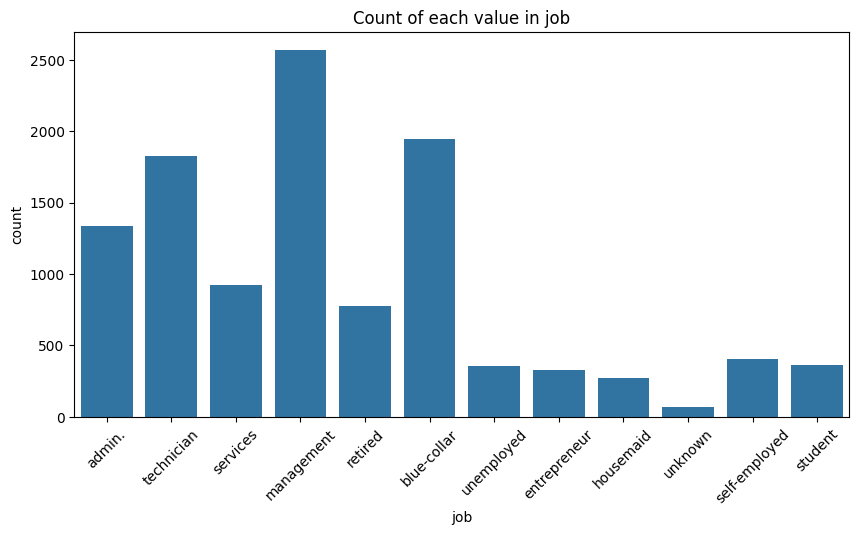

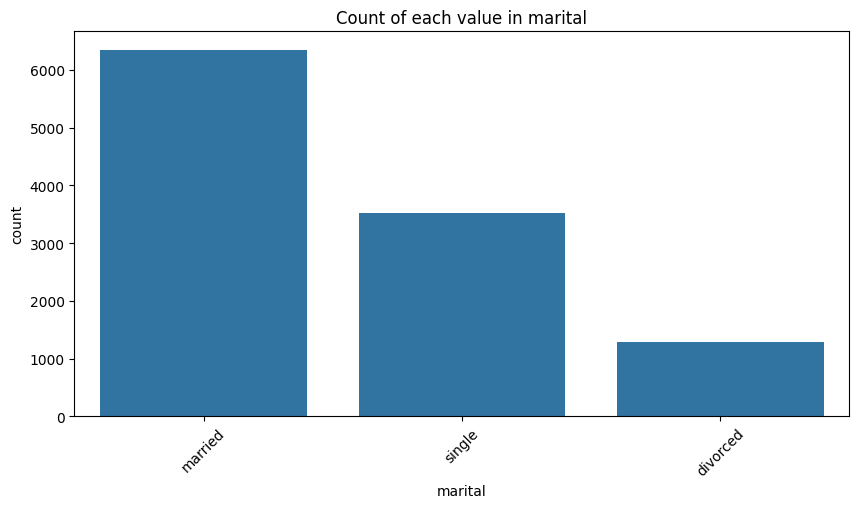

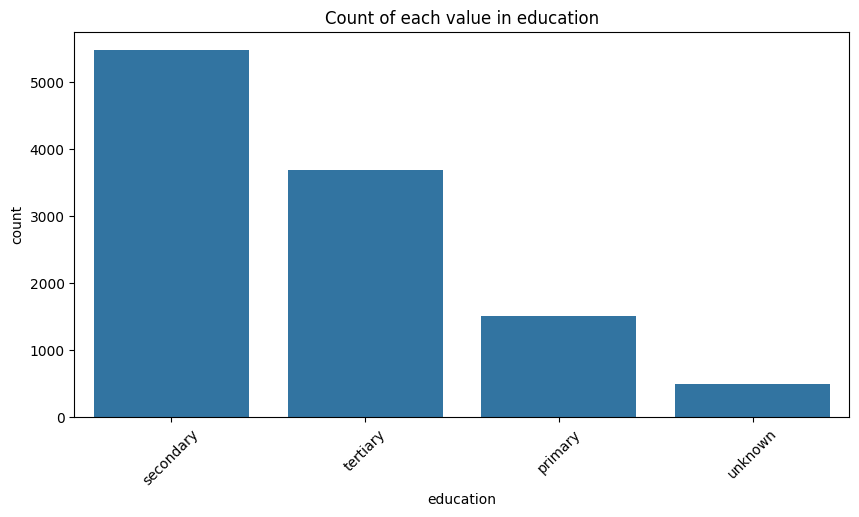

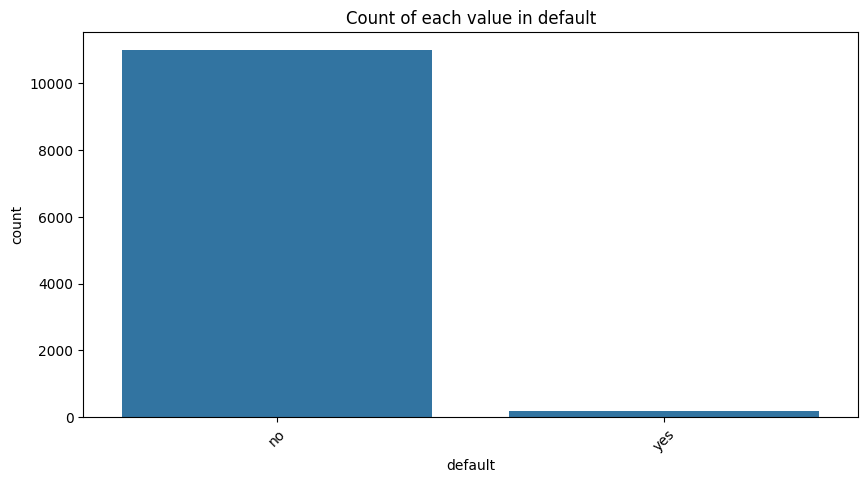

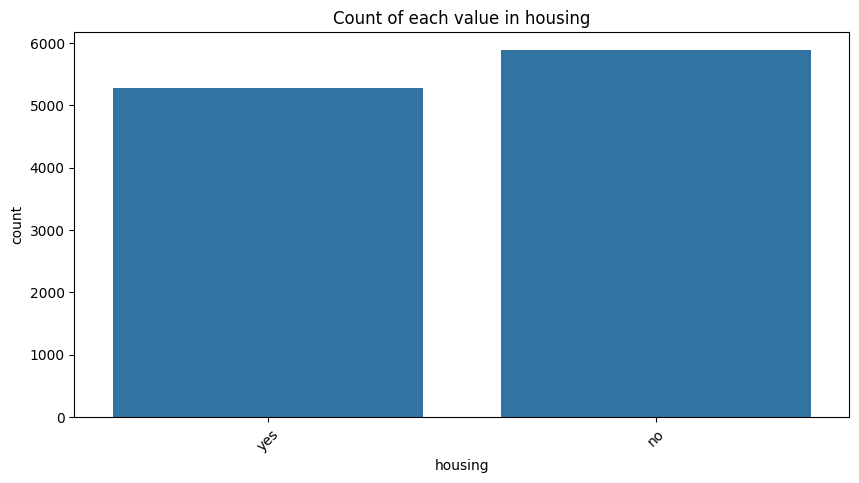

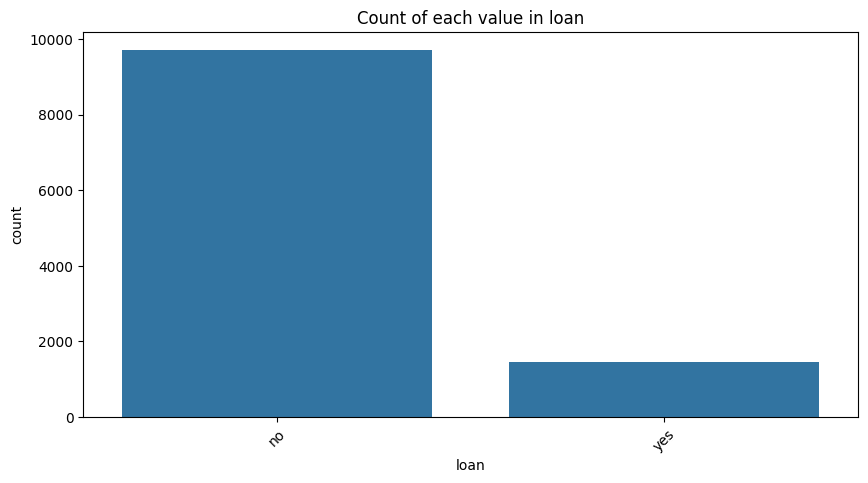

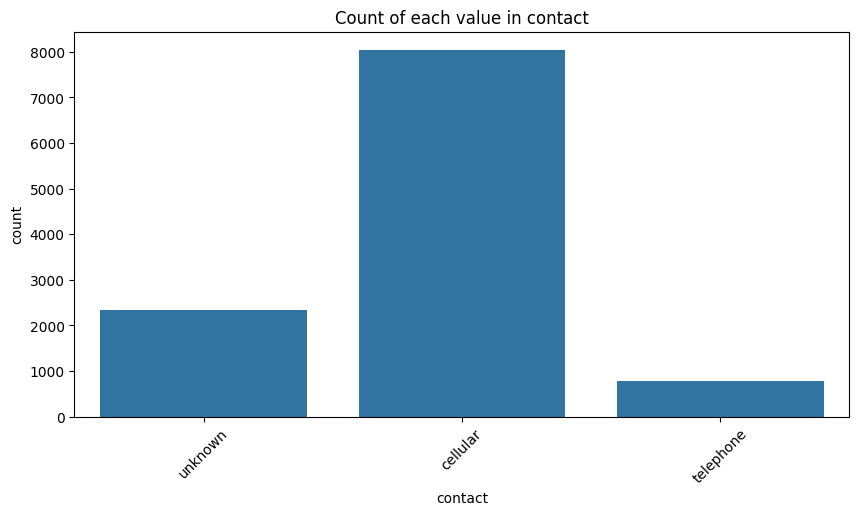

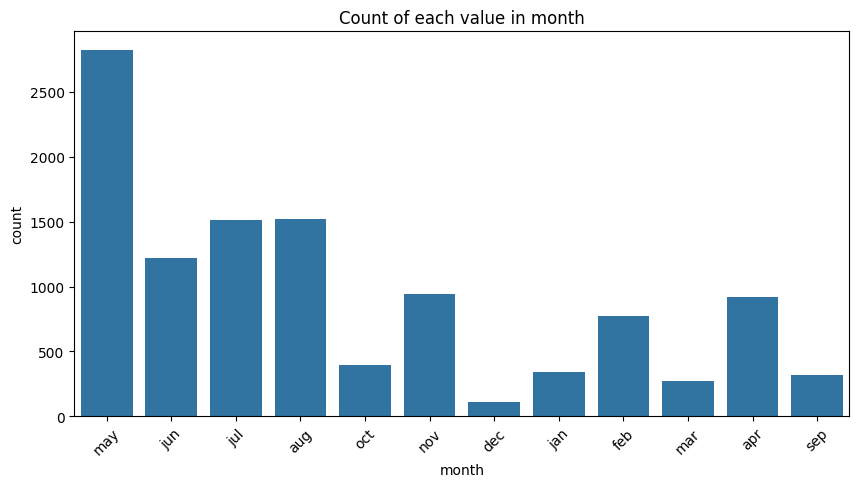

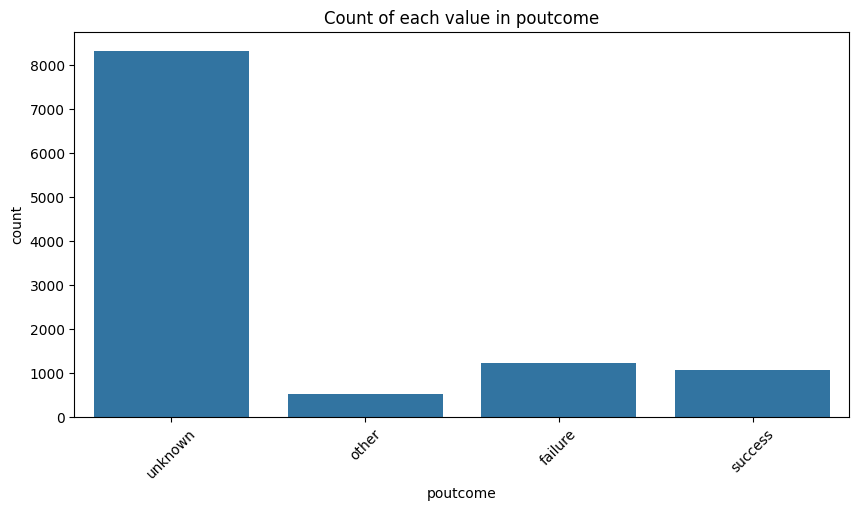

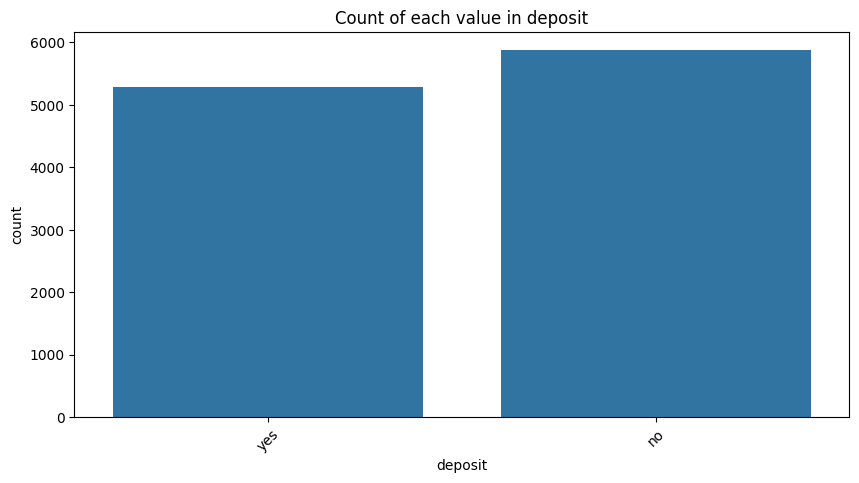

In [8]:
cat=df.select_dtypes(include='object')

for col in cat:
    plt.figure(figsize=(10, 5))

    sns.countplot(data=df, x=col)

    plt.title(f'Count of each value in {col}')
    plt.xticks(rotation=45)
    plt.show()

In [9]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [10]:
df.drop(columns=['poutcome'],inplace=True)

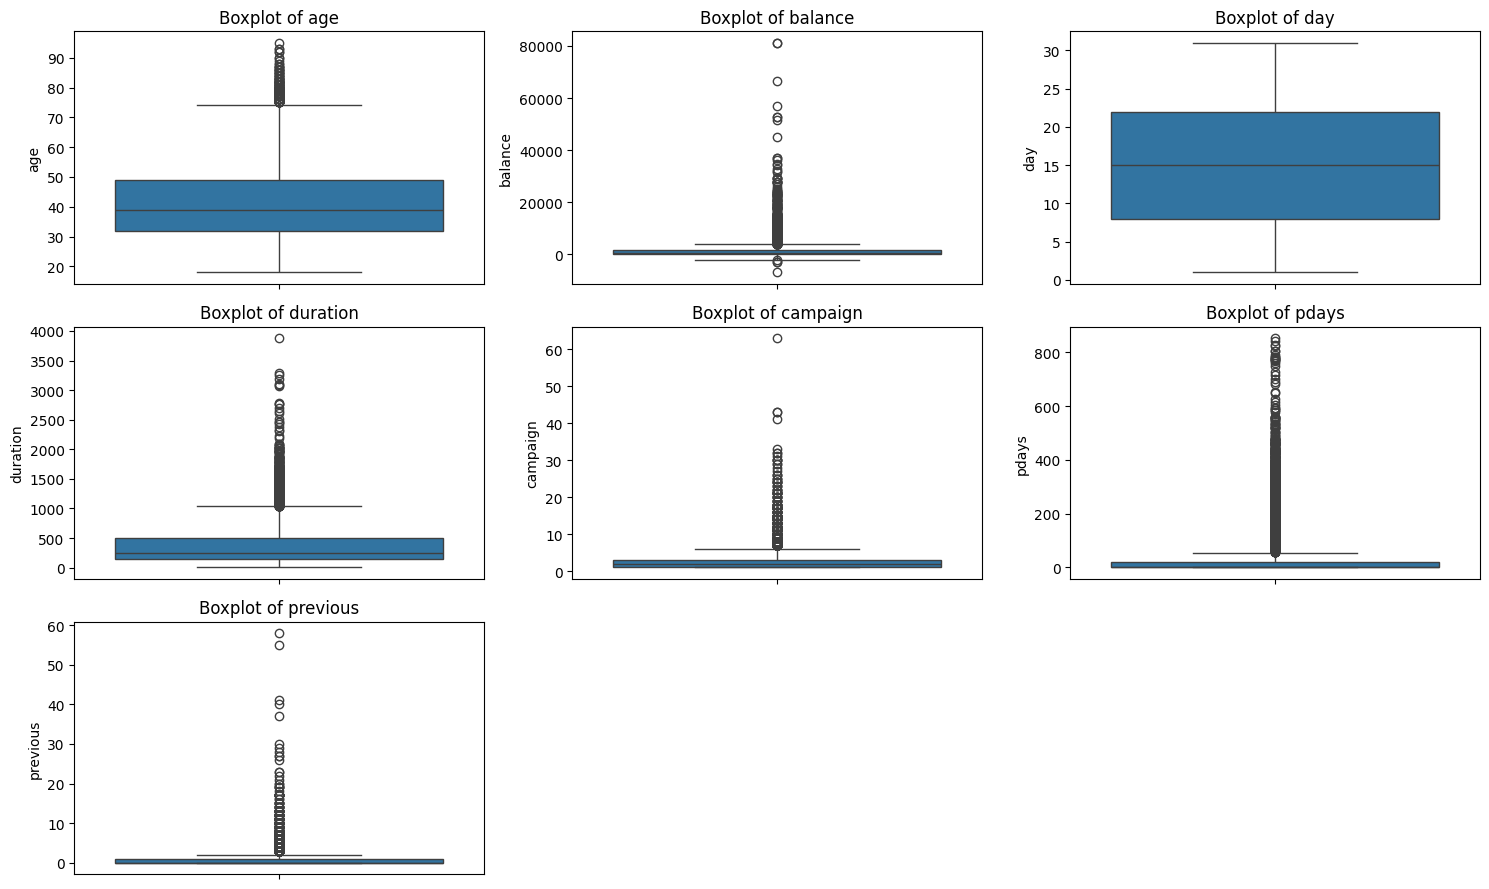

In [11]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
num_plots = len(numeric_cols)
cols_grid = 3
rows_grid = (num_plots + cols_grid - 1) // cols_grid

plt.figure(figsize=(15, 3 * rows_grid))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(rows_grid, cols_grid, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

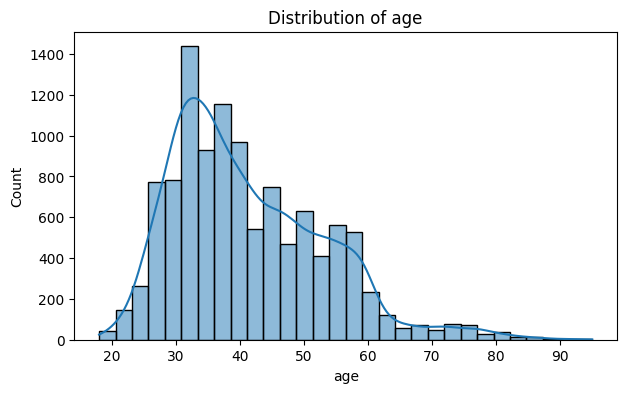

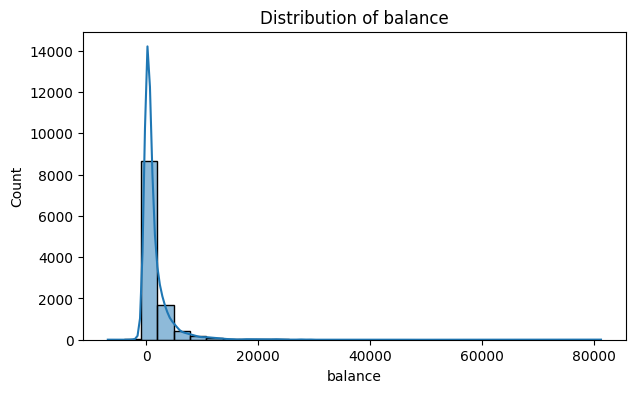

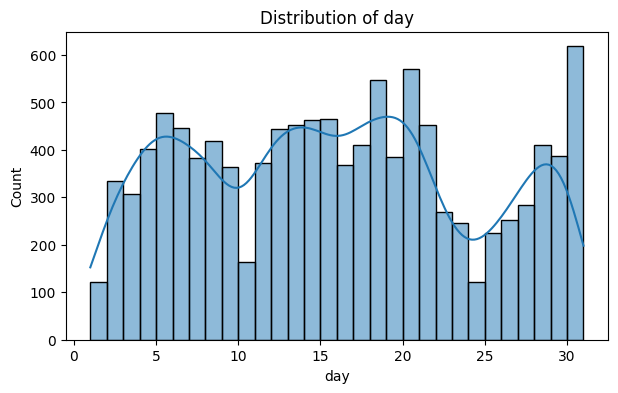

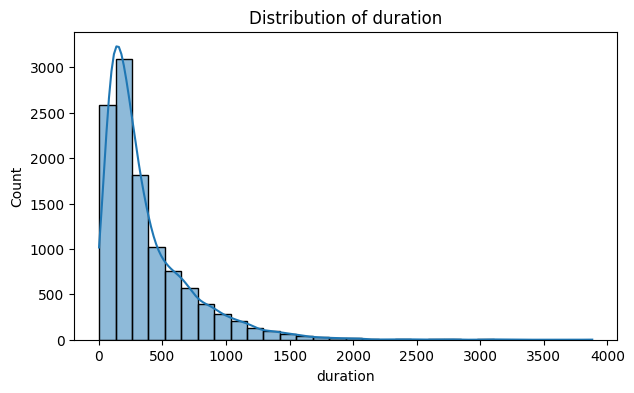

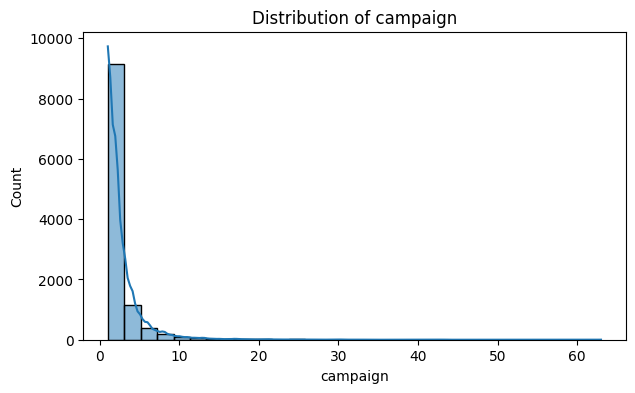

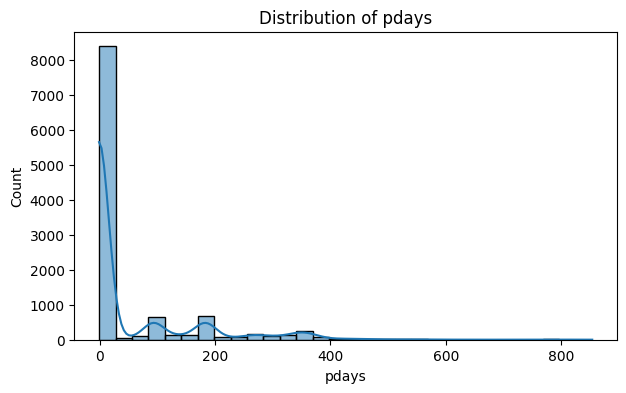

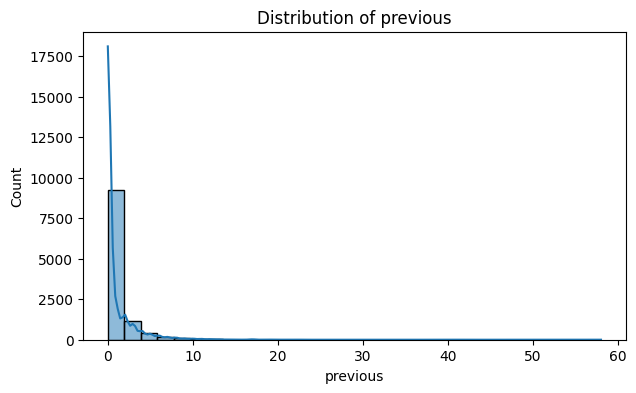

In [12]:


for col in numeric_cols:

    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")
    plt.show()


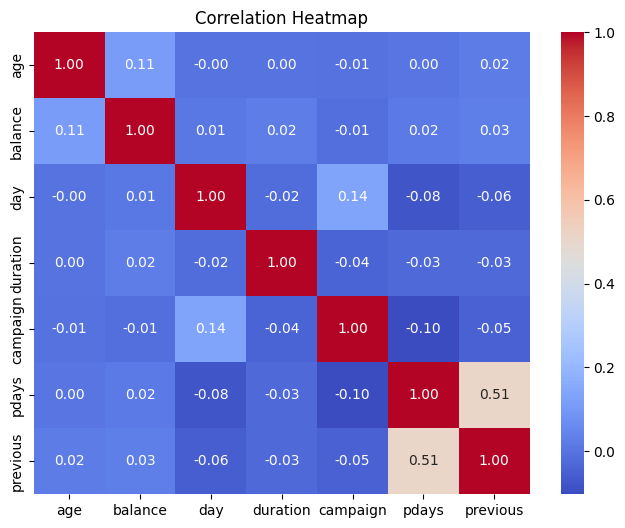

In [13]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [14]:
for col in numeric_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)

  IQR = Q3 - Q1

  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR

  outliers = df[
      (df[col] < lower) |
      (df[col] > upper)
  ]


  print("Number of Outliers:", len(outliers))

Number of Outliers: 171
Number of Outliers: 1055
Number of Outliers: 0
Number of Outliers: 636
Number of Outliers: 601
Number of Outliers: 2750
Number of Outliers: 1258


In [15]:
df_cleaned = df.copy()

for col in numeric_cols:
    Q1 = df_cleaned[col].quantile(0.25)
    Q3 = df_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df_cleaned[col] = np.where(df_cleaned[col] < lower_limit, lower_limit, df_cleaned[col])
    df_cleaned[col] = np.where(df_cleaned[col] > upper_limit, upper_limit, df_cleaned[col])

print("Outliers handled successfully via IQR capping.")
for col in numeric_cols:
    Q1 = df_cleaned[col].quantile(0.25)
    Q3 = df_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df_cleaned[(df_cleaned[col] < lower) | (df_cleaned[col] > upper)]
    print(f"{col}: Remaining outliers after capping = {len(outliers)}")

Outliers handled successfully via IQR capping.
age: Remaining outliers after capping = 0
balance: Remaining outliers after capping = 0
day: Remaining outliers after capping = 0
duration: Remaining outliers after capping = 0
campaign: Remaining outliers after capping = 0
pdays: Remaining outliers after capping = 0
previous: Remaining outliers after capping = 0


In [16]:
df.shape

(11162, 16)

In [17]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,yes


In [18]:
x=df.drop('deposit',axis=1)
y=df['deposit']
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [19]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(8929, 15)
(2233, 15)
(8929,)
(2233,)


In [20]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
cat = x_train.select_dtypes(include='object')
for col in cat:
    combined_series = pd.concat([x_train[col], x_test[col]]).astype(str)
    le.fit(combined_series)
    x_train[col] = le.transform(x_train[col].astype(str))
    x_test[col] = le.transform(x_test[col].astype(str))
    y_train = le.fit_transform(y_train)
    y_test = le.transform(y_test)


In [21]:
from sklearn.preprocessing import StandardScaler
scalar=StandardScaler()
for i in x_train.select_dtypes(include='number'):
    x_train[[i]] = scalar.fit_transform(x_train[[i]])
    x_test[[i]] = scalar.transform(x_test[[i]])


In [22]:
pip install xgboost lightgbm catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 57.0 MB/s  0:00:01


In [23]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [24]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

In [25]:
from sklearn.model_selection import cross_validate, KFold
import pandas as pd

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1'
}

cv_results = {}

# We will perform 5-fold cross-validation on our top-performing models
selected_models = {
    "LightGBM": models["LightGBM"],
    "CatBoost": models["CatBoost"],
    "XGBoost": models["XGBoost"],
    "Random Forest": models["Random Forest"]
}

for name, model in selected_models.items():
    cv = cross_validate(model, x_train, y_train, cv=kfold, scoring=scoring, return_train_score=True, n_jobs=-1)
    cv_results[name] = {
        'Train Accuracy': cv['train_Accuracy'].mean(),
        'CV Accuracy': cv['test_Accuracy'].mean(),
        'CV Precision': cv['test_Precision'].mean(),
        'CV Recall': cv['test_Recall'].mean(),
        'CV F1 Score': cv['test_F1'].mean(),
        'Fit time (s)': cv['fit_time'].mean(),
    }
    print(f"{name:15s} -> CV Accuracy: {cv_results[name]['CV Accuracy']:.4f} | CV F1: {cv_results[name]['CV F1 Score']:.4f}")

# Display as DataFrame
cv_results_df = pd.DataFrame(cv_results).T
display(cv_results_df)

LightGBM        -> CV Accuracy: 0.8579 | CV F1: 0.8543
CatBoost        -> CV Accuracy: 0.8628 | CV F1: 0.8588
XGBoost         -> CV Accuracy: 0.8554 | CV F1: 0.8506
Random Forest   -> CV Accuracy: 0.8435 | CV F1: 0.8395


,Train Accuracy,CV Accuracy,CV Precision,CV Recall,CV F1 Score,Fit time (s)
LightGBM,0.917208,0.857878,0.828573,0.881717,0.854294,0.226874
CatBoost,0.916116,0.862806,0.836219,0.882716,0.858820,7.791419
XGBoost,0.971945,0.855415,0.831524,0.870644,0.850564,0.751881
Random Forest,1.000000,0.843543,0.814558,0.866107,0.839526,3.465855


In [26]:
from tqdm import tqdm

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[950 216]
 [262 805]]


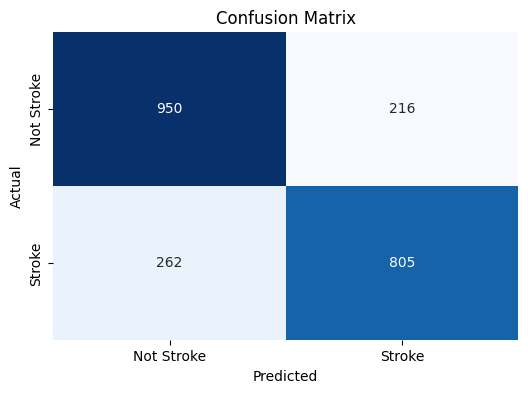


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.78      0.81      0.80      1166
      Stroke       0.79      0.75      0.77      1067

    accuracy                           0.79      2233
   macro avg       0.79      0.78      0.79      2233
weighted avg       0.79      0.79      0.79      2233

ROC-AUC: 0.8654585322018259


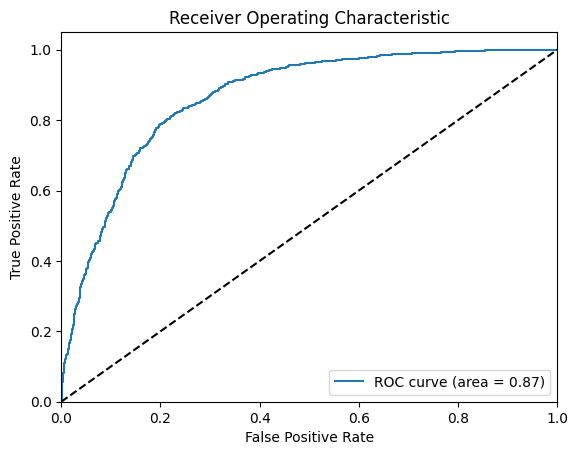

PR AUC: 0.8301481249418908


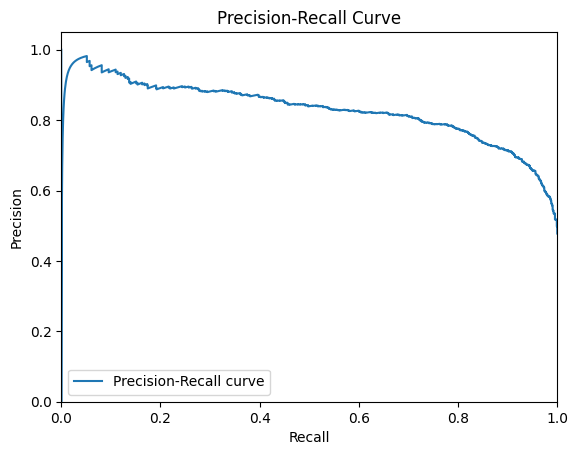

  8%|▊         | 1/13 [00:00<00:06,  1.74it/s]


Confusion Matrix:
 [[946 220]
 [302 765]]


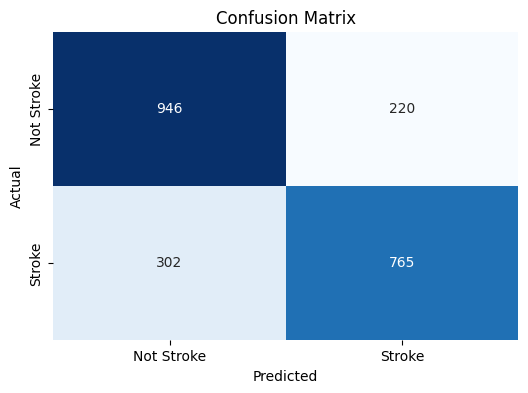


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.76      0.81      0.78      1166
      Stroke       0.78      0.72      0.75      1067

    accuracy                           0.77      2233
   macro avg       0.77      0.76      0.76      2233
weighted avg       0.77      0.77      0.77      2233

ROC-AUC: 0.835787406701272


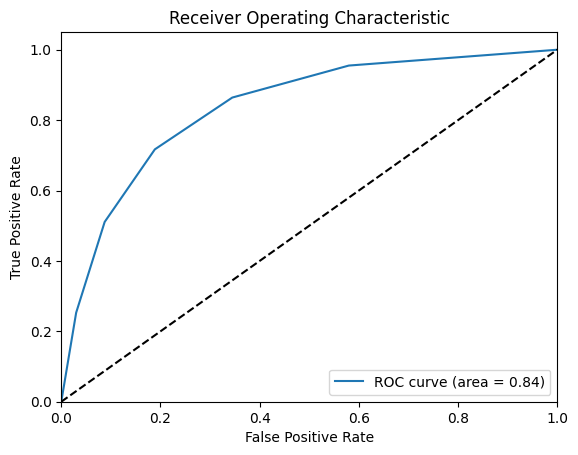

PR AUC: 0.77985625765329


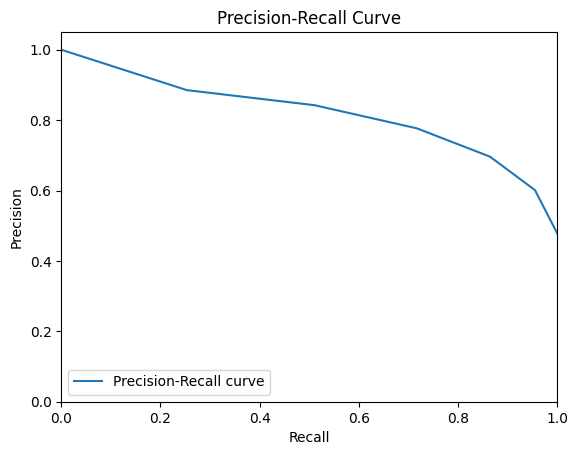

 15%|█▌        | 2/13 [00:06<00:42,  3.90s/it]


Confusion Matrix:
 [[924 242]
 [186 881]]


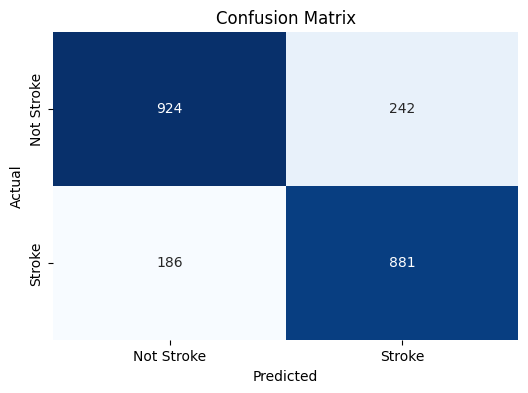


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.83      0.79      0.81      1166
      Stroke       0.78      0.83      0.80      1067

    accuracy                           0.81      2233
   macro avg       0.81      0.81      0.81      2233
weighted avg       0.81      0.81      0.81      2233

ROC-AUC: 0.8831320401053916


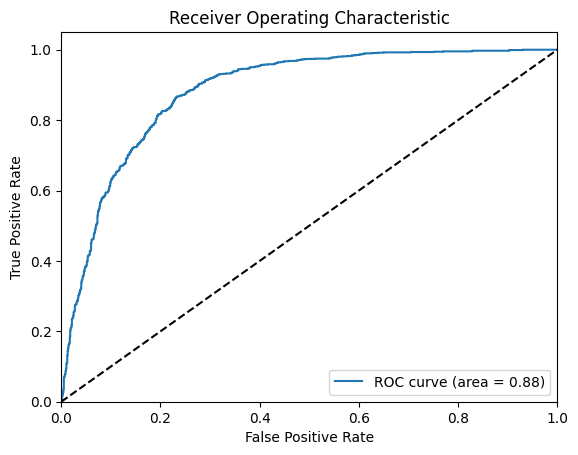

PR AUC: 0.8403765884306396


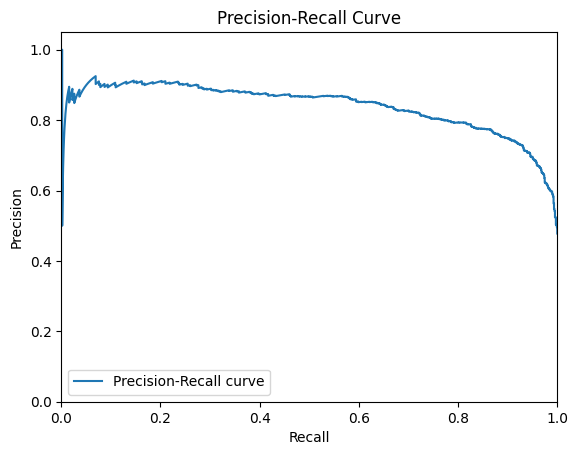

 23%|██▎       | 3/13 [00:37<02:42, 16.20s/it]


Confusion Matrix:
 [[903 263]
 [258 809]]


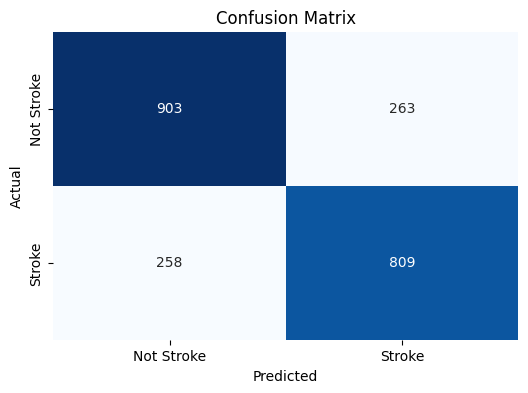


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.78      0.77      0.78      1166
      Stroke       0.75      0.76      0.76      1067

    accuracy                           0.77      2233
   macro avg       0.77      0.77      0.77      2233
weighted avg       0.77      0.77      0.77      2233

ROC-AUC: 0.7663215504588778


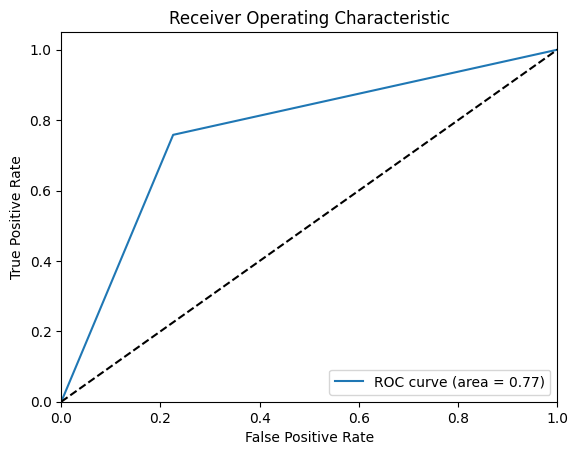

PR AUC: 0.6877264377440134


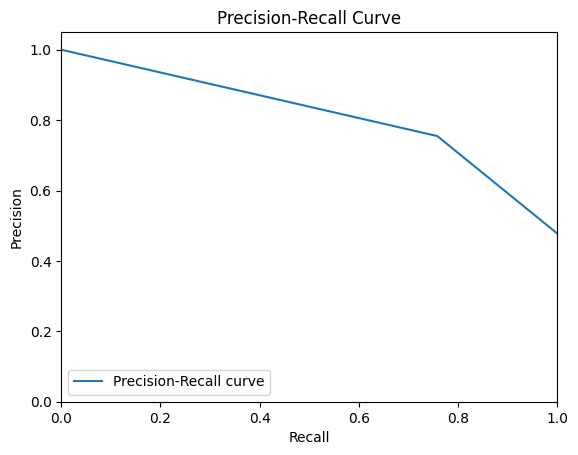

 31%|███       | 4/13 [00:38<01:29, 10.00s/it]


Confusion Matrix:
 [[784 382]
 [192 875]]


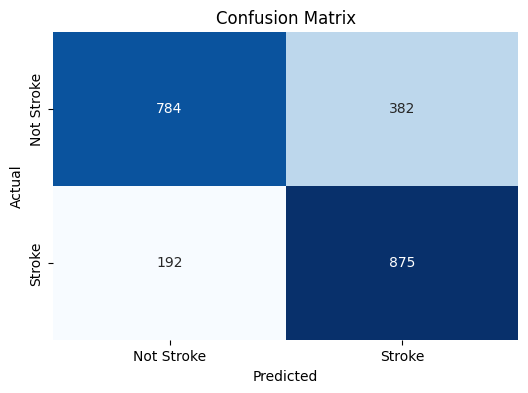


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.80      0.67      0.73      1166
      Stroke       0.70      0.82      0.75      1067

    accuracy                           0.74      2233
   macro avg       0.75      0.75      0.74      2233
weighted avg       0.75      0.74      0.74      2233

ROC-AUC: 0.8211107913854107


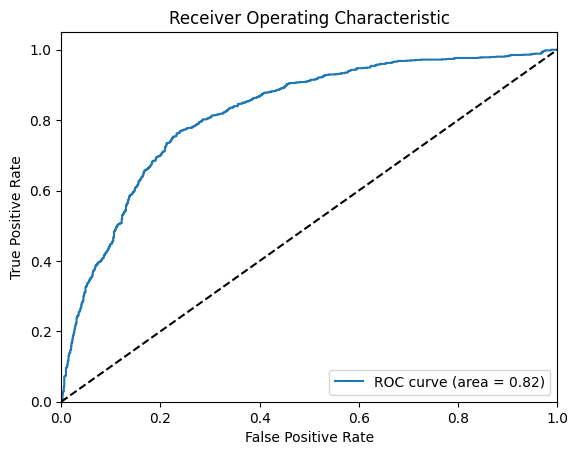

PR AUC: 0.7832337925298261


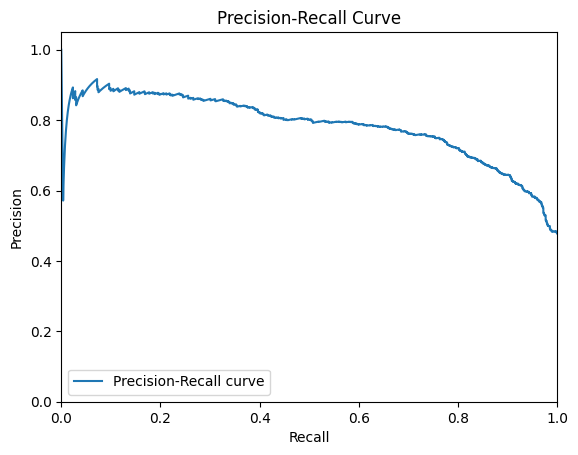

 38%|███▊      | 5/13 [00:38<00:52,  6.54s/it]


Confusion Matrix:
 [[945 221]
 [143 924]]


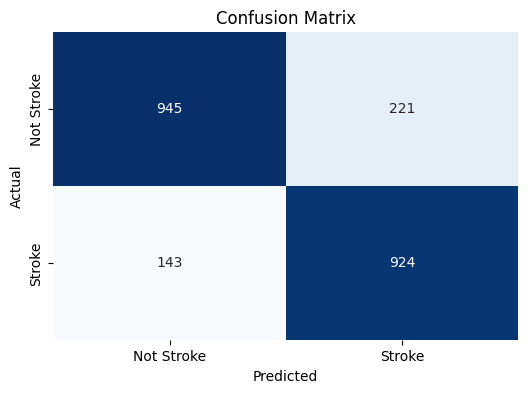


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.81      0.84      1166
      Stroke       0.81      0.87      0.84      1067

    accuracy                           0.84      2233
   macro avg       0.84      0.84      0.84      2233
weighted avg       0.84      0.84      0.84      2233

ROC-AUC: 0.9081561133072159


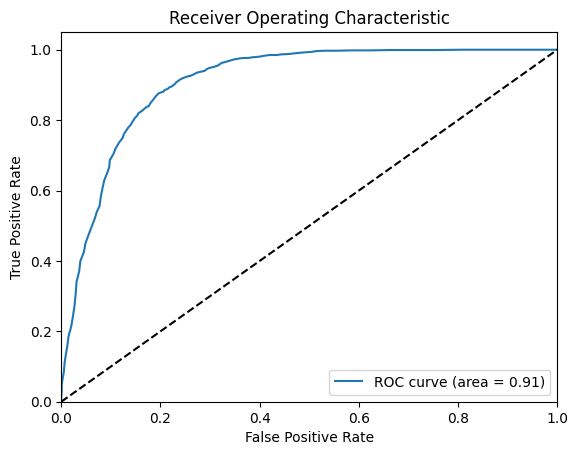

PR AUC: 0.8709045252828266


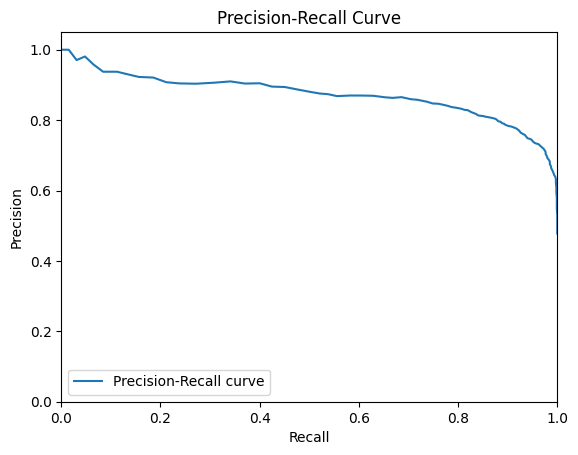

 46%|████▌     | 6/13 [00:40<00:34,  4.96s/it]


Confusion Matrix:
 [[945 221]
 [162 905]]


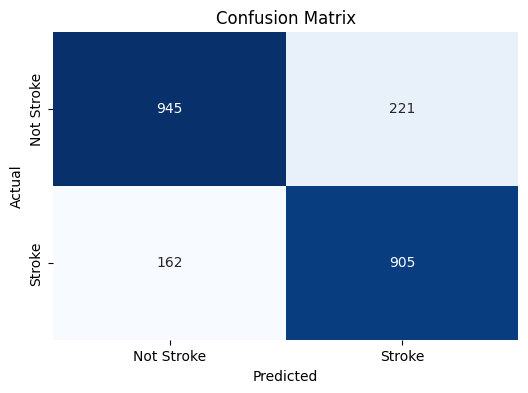


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.85      0.81      0.83      1166
      Stroke       0.80      0.85      0.83      1067

    accuracy                           0.83      2233
   macro avg       0.83      0.83      0.83      2233
weighted avg       0.83      0.83      0.83      2233

ROC-AUC: 0.9053790544657196


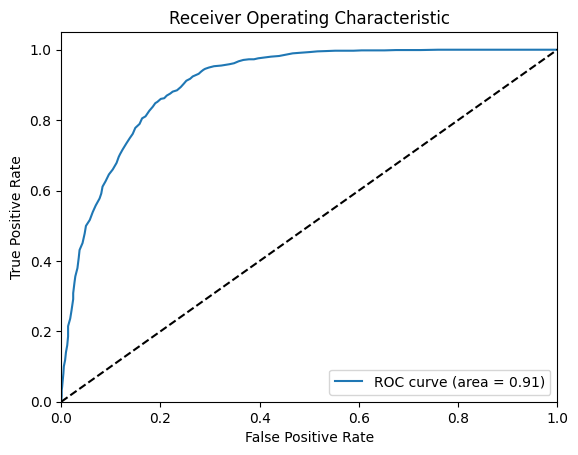

PR AUC: 0.8711278165945212


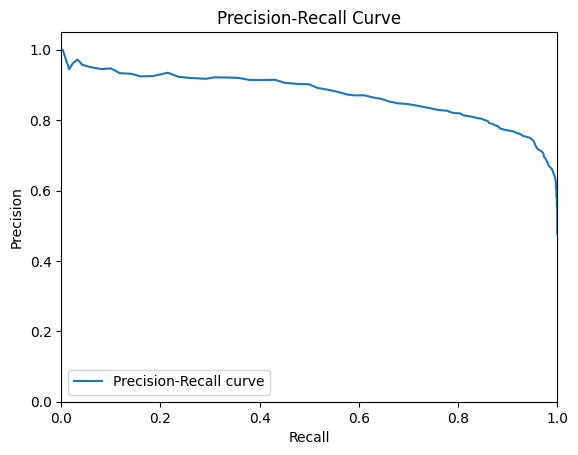

 54%|█████▍    | 7/13 [00:42<00:23,  3.86s/it]


Confusion Matrix:
 [[942 224]
 [242 825]]


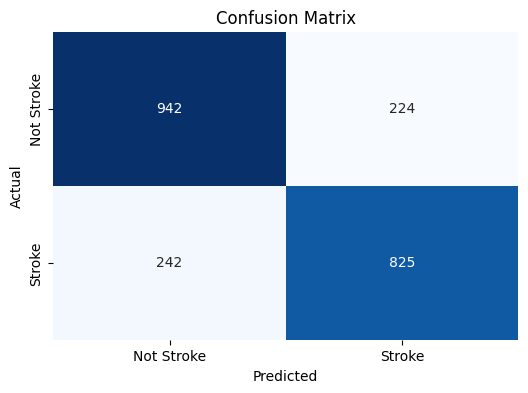


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.80      0.81      0.80      1166
      Stroke       0.79      0.77      0.78      1067

    accuracy                           0.79      2233
   macro avg       0.79      0.79      0.79      2233
weighted avg       0.79      0.79      0.79      2233

ROC-AUC: 0.8746007224371887


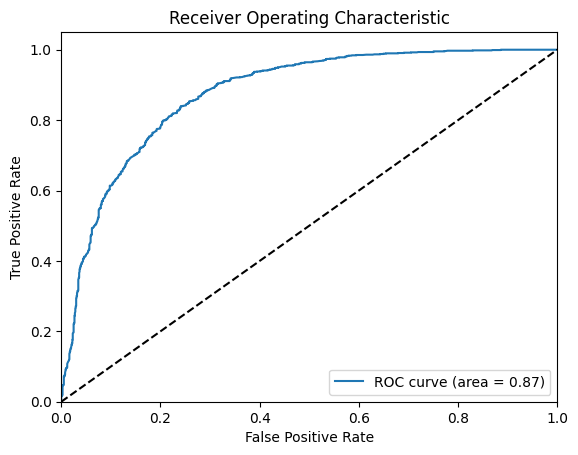

PR AUC: 0.8371880150450572


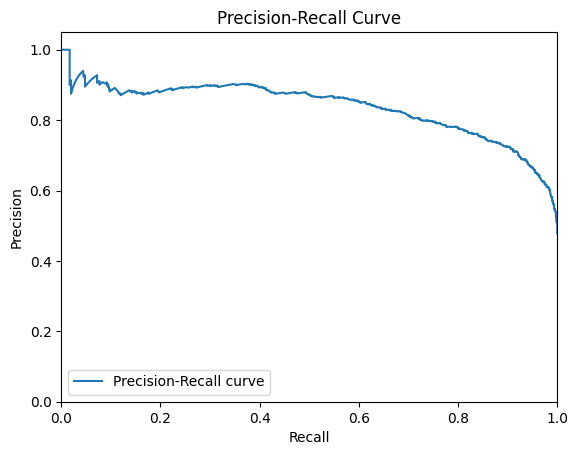

 62%|██████▏   | 8/13 [00:42<00:14,  2.89s/it]


Confusion Matrix:
 [[942 224]
 [166 901]]


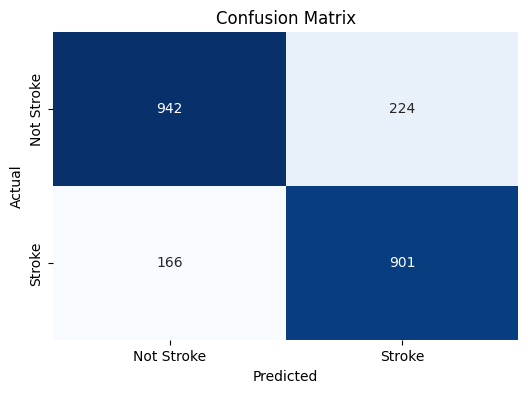


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.85      0.81      0.83      1166
      Stroke       0.80      0.84      0.82      1067

    accuracy                           0.83      2233
   macro avg       0.83      0.83      0.83      2233
weighted avg       0.83      0.83      0.83      2233

ROC-AUC: 0.9085101782622604


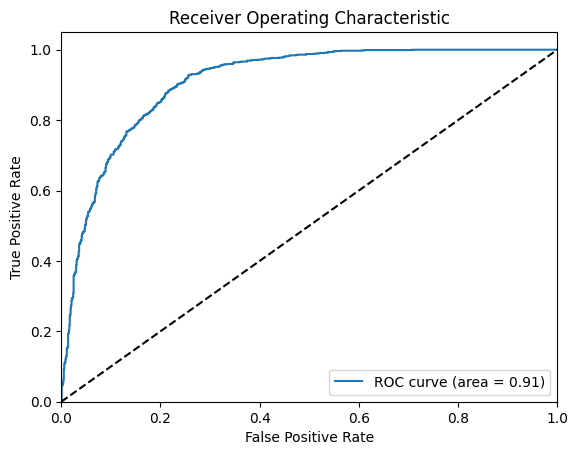

PR AUC: 0.8766449926690107


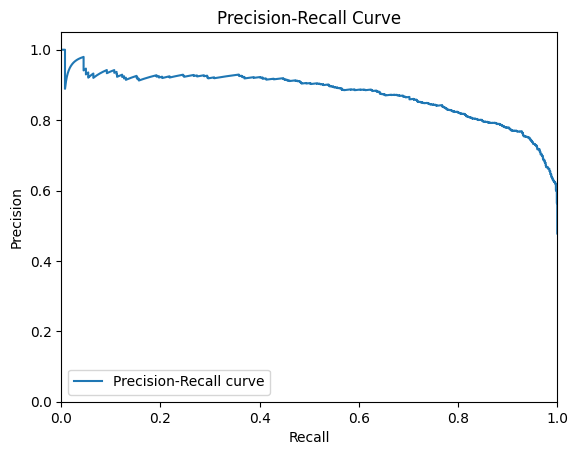

 69%|██████▉   | 9/13 [00:44<00:10,  2.57s/it]


Confusion Matrix:
 [[957 209]
 [144 923]]


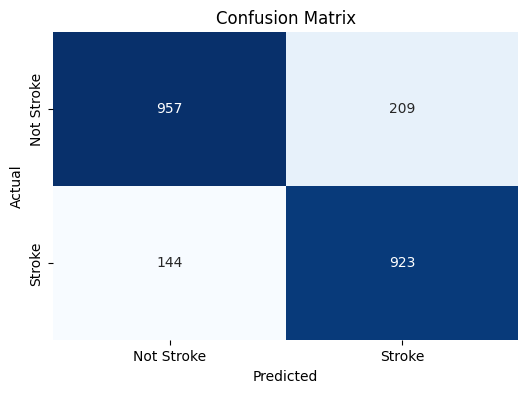


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.82      0.84      1166
      Stroke       0.82      0.87      0.84      1067

    accuracy                           0.84      2233
   macro avg       0.84      0.84      0.84      2233
weighted avg       0.84      0.84      0.84      2233

ROC-AUC: 0.919381700508471


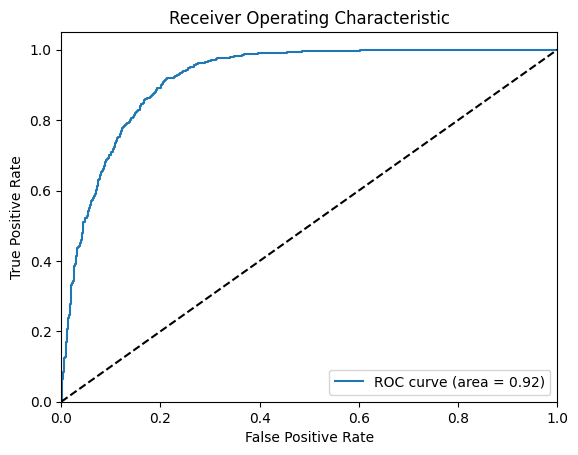

PR AUC: 0.8867562483048582


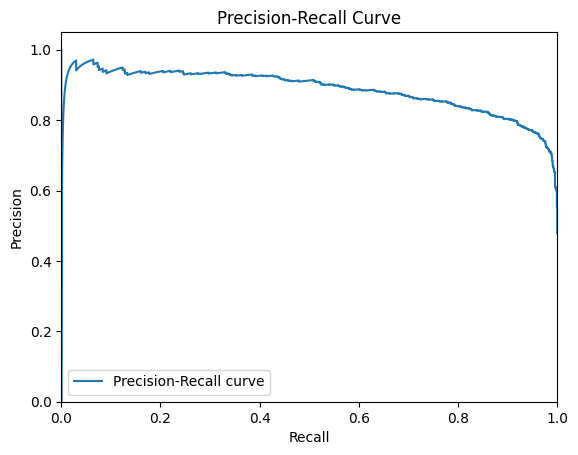

 77%|███████▋  | 10/13 [00:45<00:06,  2.10s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [20:11:26] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[968 198]
 [151 916]]


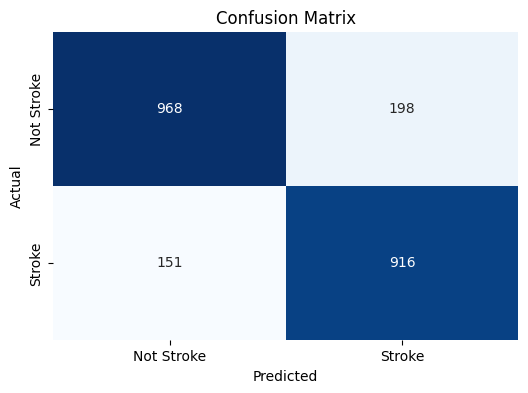


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.83      0.85      1166
      Stroke       0.82      0.86      0.84      1067

    accuracy                           0.84      2233
   macro avg       0.84      0.84      0.84      2233
weighted avg       0.84      0.84      0.84      2233

ROC-AUC: 0.9157839825997772


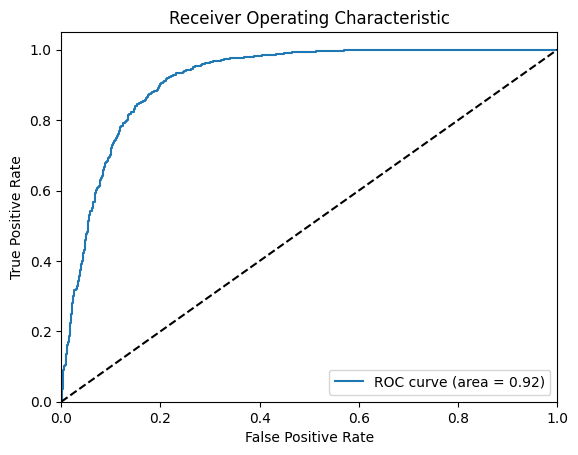

PR AUC: 0.8763659035547554


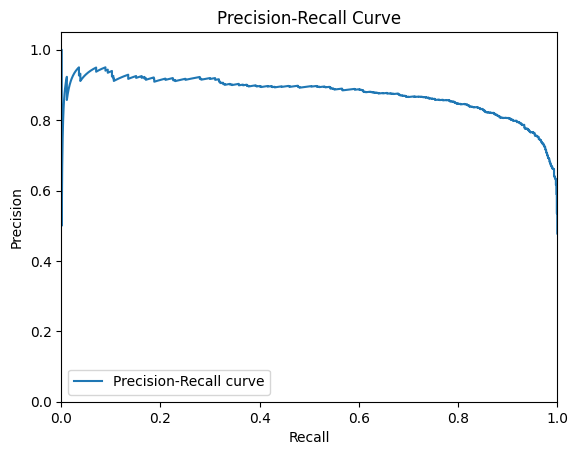

 85%|████████▍ | 11/13 [00:46<00:03,  1.72s/it]


Confusion Matrix:
 [[970 196]
 [139 928]]


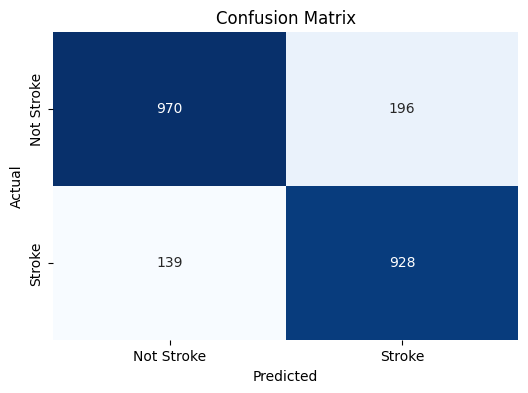


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.83      0.85      1166
      Stroke       0.83      0.87      0.85      1067

    accuracy                           0.85      2233
   macro avg       0.85      0.85      0.85      2233
weighted avg       0.85      0.85      0.85      2233

ROC-AUC: 0.92276802435774


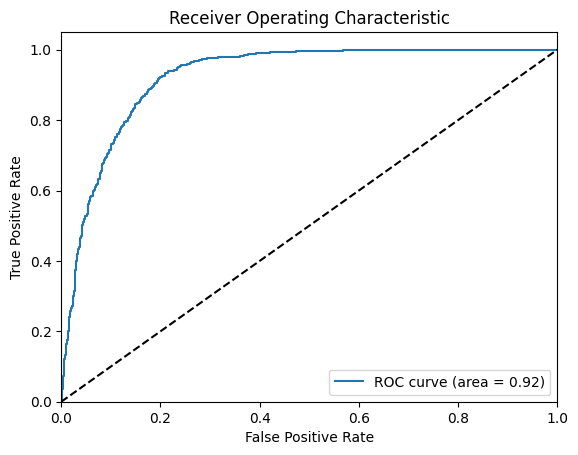

PR AUC: 0.8878339293843491


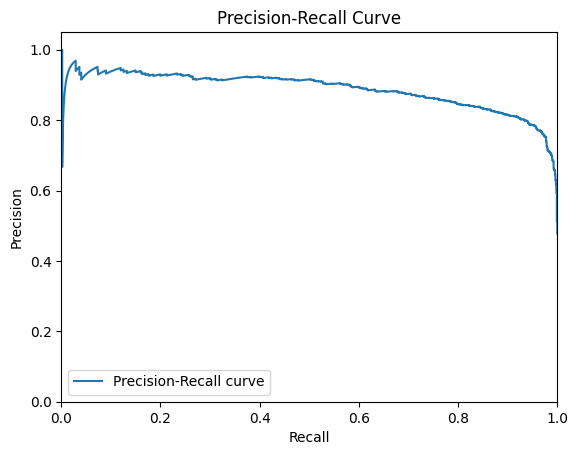

 92%|█████████▏| 12/13 [00:51<00:02,  2.70s/it]

[LightGBM] [Info] Number of positive: 4222, number of negative: 4707
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000910 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 969
[LightGBM] [Info] Number of data points in the train set: 8929, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.472841 -> initscore=-0.108742
[LightGBM] [Info] Start training from score -0.108742

Confusion Matrix:
 [[952 214]
 [142 925]]


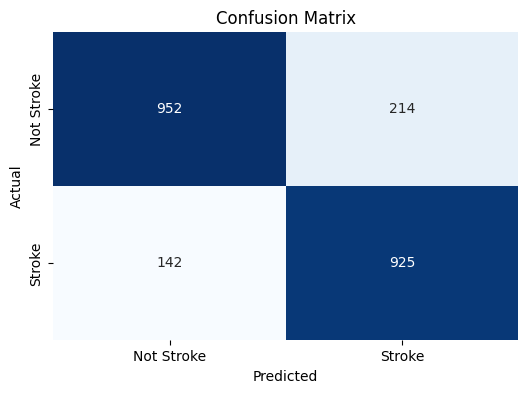


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.82      0.84      1166
      Stroke       0.81      0.87      0.84      1067

    accuracy                           0.84      2233
   macro avg       0.84      0.84      0.84      2233
weighted avg       0.84      0.84      0.84      2233

ROC-AUC: 0.9186550836654284


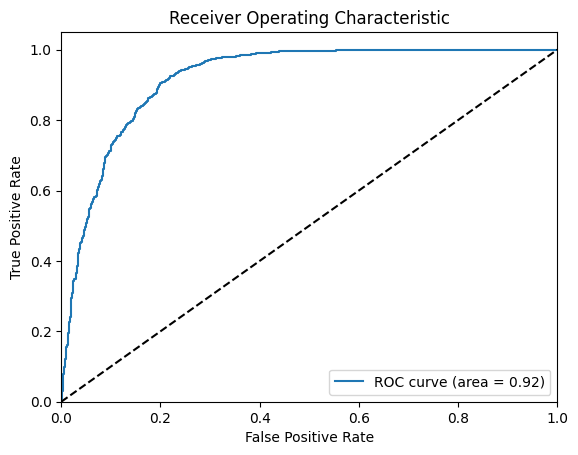

PR AUC: 0.8835778901188349


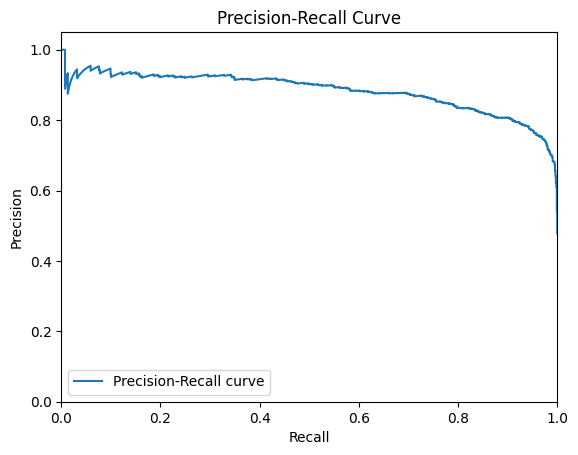

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[950 216]
 [262 805]]


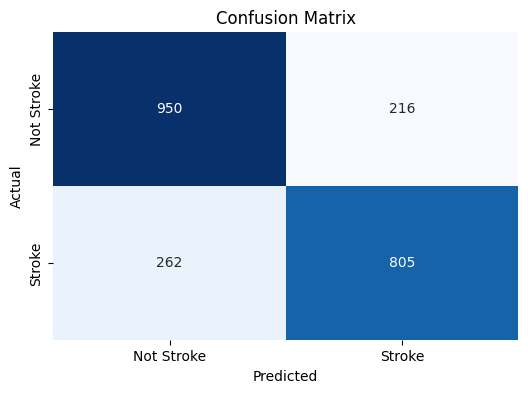


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.78      0.81      0.80      1166
      Stroke       0.79      0.75      0.77      1067

    accuracy                           0.79      2233
   macro avg       0.79      0.78      0.79      2233
weighted avg       0.79      0.79      0.79      2233

ROC-AUC: 0.8654585322018259


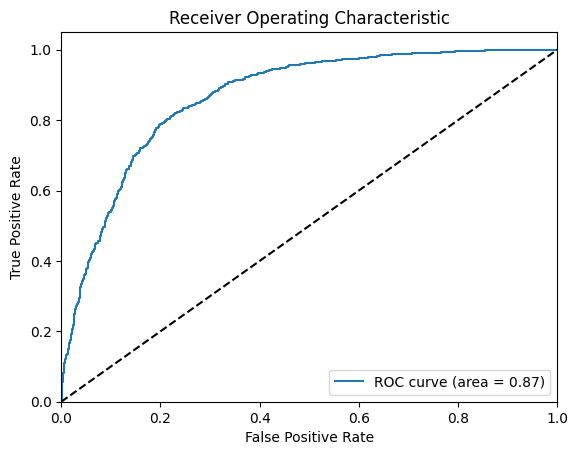

PR AUC: 0.8301481249418908


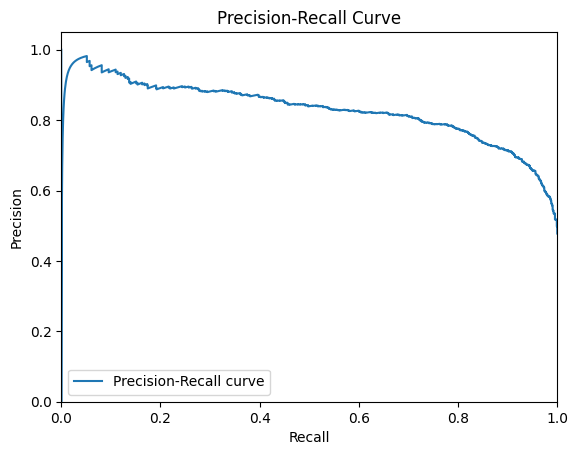

  8%|▊         | 1/13 [00:00<00:05,  2.03it/s]


Confusion Matrix:
 [[946 220]
 [302 765]]


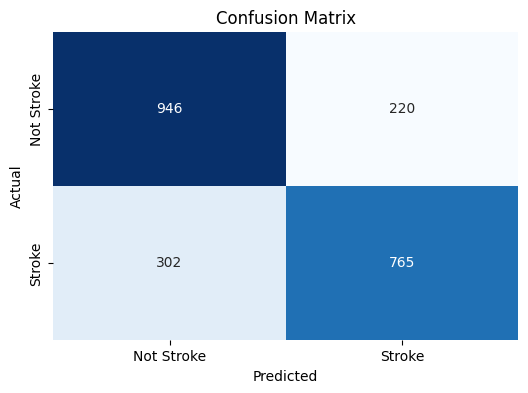


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.76      0.81      0.78      1166
      Stroke       0.78      0.72      0.75      1067

    accuracy                           0.77      2233
   macro avg       0.77      0.76      0.76      2233
weighted avg       0.77      0.77      0.77      2233

ROC-AUC: 0.835787406701272


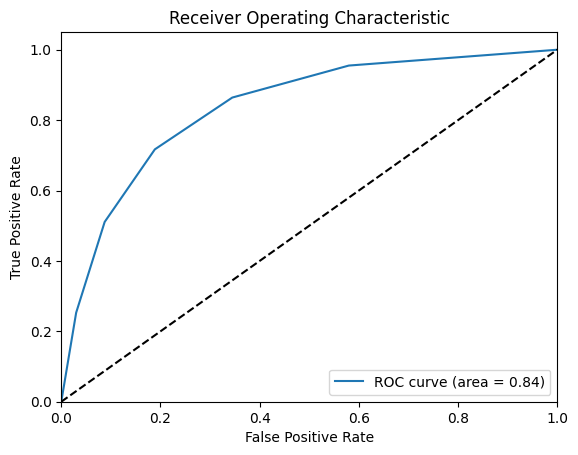

PR AUC: 0.77985625765329


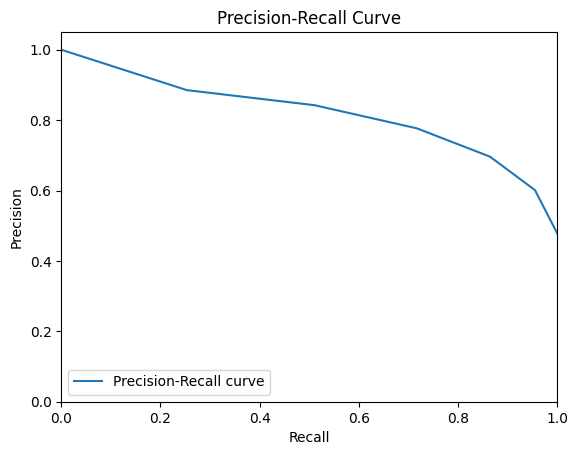

 15%|█▌        | 2/13 [00:03<00:20,  1.88s/it]


Confusion Matrix:
 [[924 242]
 [186 881]]


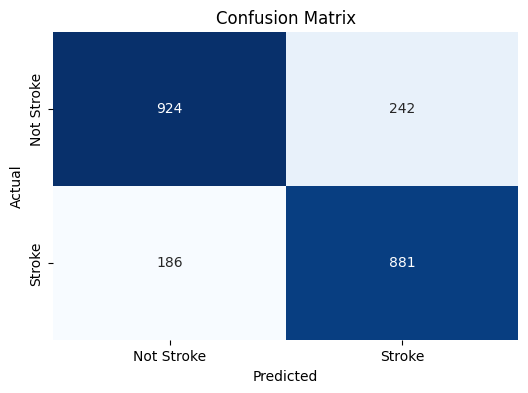


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.83      0.79      0.81      1166
      Stroke       0.78      0.83      0.80      1067

    accuracy                           0.81      2233
   macro avg       0.81      0.81      0.81      2233
weighted avg       0.81      0.81      0.81      2233

ROC-AUC: 0.8831320401053916


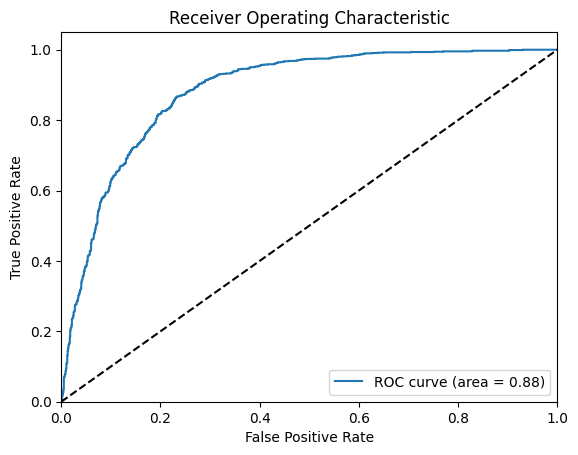

PR AUC: 0.8403765884306396


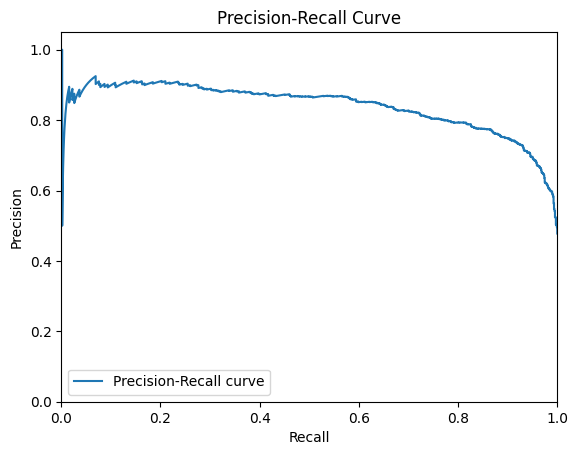

 23%|██▎       | 3/13 [00:21<01:31,  9.13s/it]


Confusion Matrix:
 [[903 263]
 [258 809]]


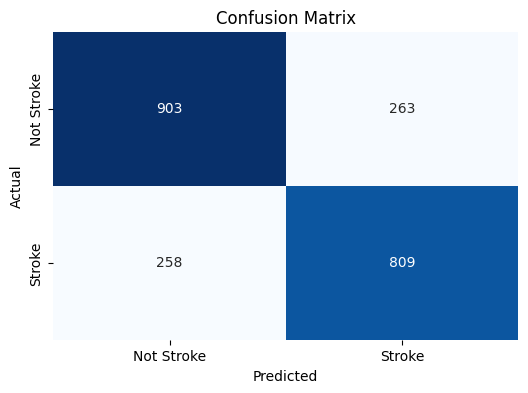


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.78      0.77      0.78      1166
      Stroke       0.75      0.76      0.76      1067

    accuracy                           0.77      2233
   macro avg       0.77      0.77      0.77      2233
weighted avg       0.77      0.77      0.77      2233

ROC-AUC: 0.7663215504588778


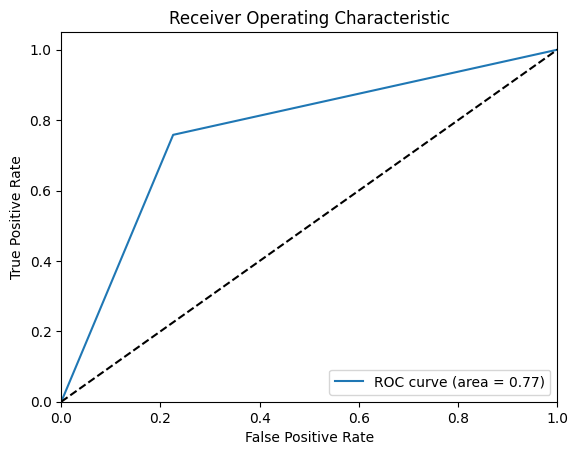

PR AUC: 0.6877264377440134


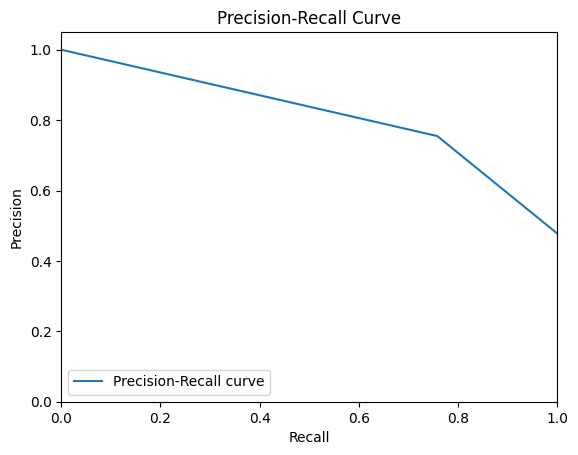

 31%|███       | 4/13 [00:21<00:51,  5.73s/it]


Confusion Matrix:
 [[784 382]
 [192 875]]


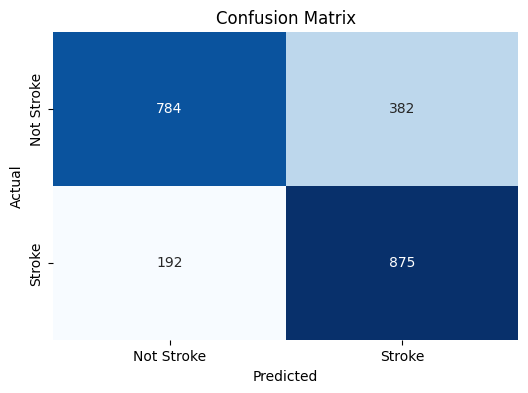


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.80      0.67      0.73      1166
      Stroke       0.70      0.82      0.75      1067

    accuracy                           0.74      2233
   macro avg       0.75      0.75      0.74      2233
weighted avg       0.75      0.74      0.74      2233

ROC-AUC: 0.8211107913854107


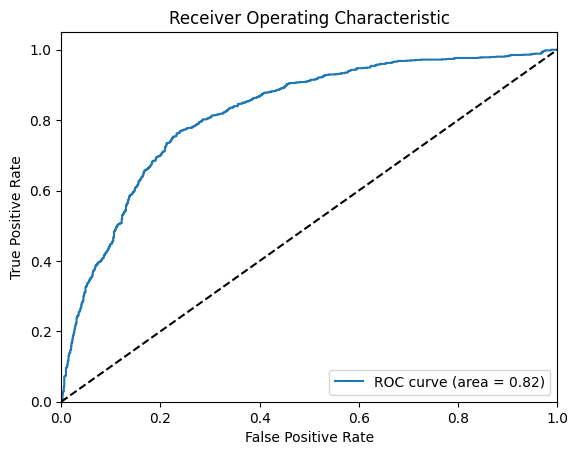

PR AUC: 0.7832337925298261


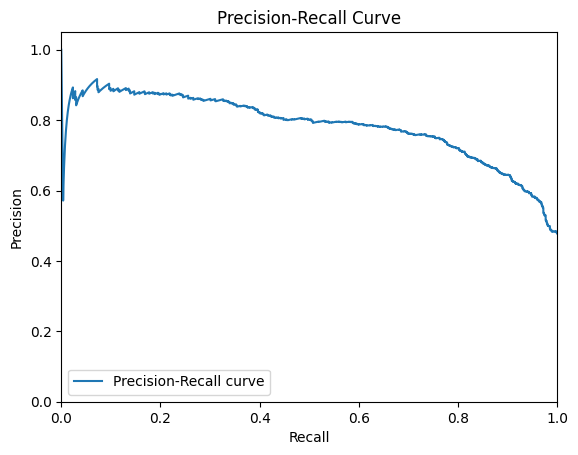

 38%|███▊      | 5/13 [00:22<00:31,  3.88s/it]


Confusion Matrix:
 [[945 221]
 [143 924]]


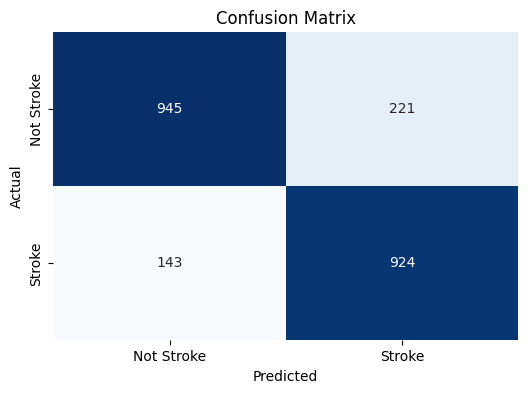


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.81      0.84      1166
      Stroke       0.81      0.87      0.84      1067

    accuracy                           0.84      2233
   macro avg       0.84      0.84      0.84      2233
weighted avg       0.84      0.84      0.84      2233

ROC-AUC: 0.9081561133072159


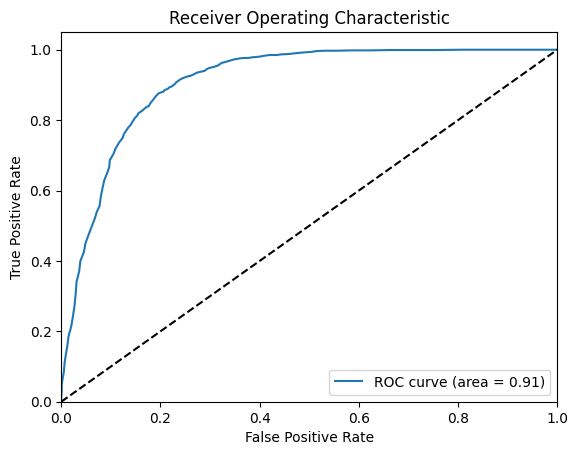

PR AUC: 0.8709045252828266


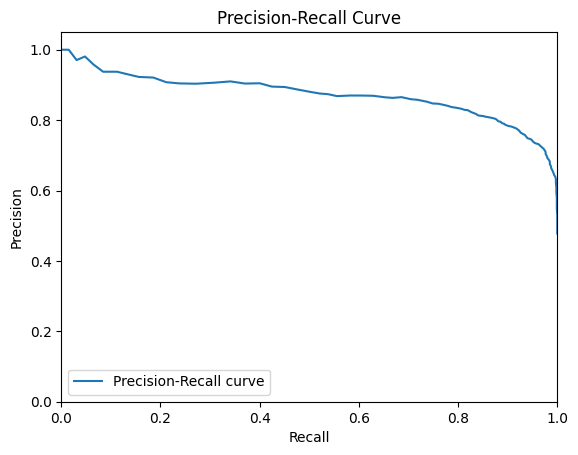

 46%|████▌     | 6/13 [00:24<00:24,  3.47s/it]


Confusion Matrix:
 [[945 221]
 [162 905]]


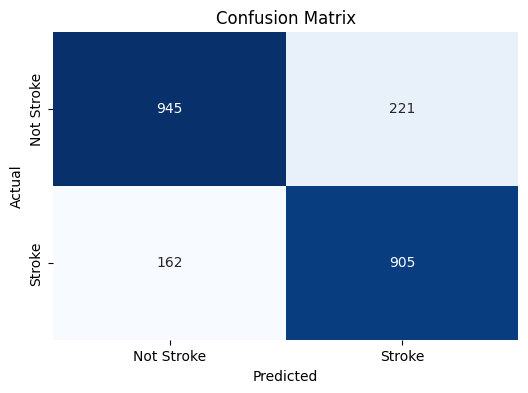


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.85      0.81      0.83      1166
      Stroke       0.80      0.85      0.83      1067

    accuracy                           0.83      2233
   macro avg       0.83      0.83      0.83      2233
weighted avg       0.83      0.83      0.83      2233

ROC-AUC: 0.9053790544657196


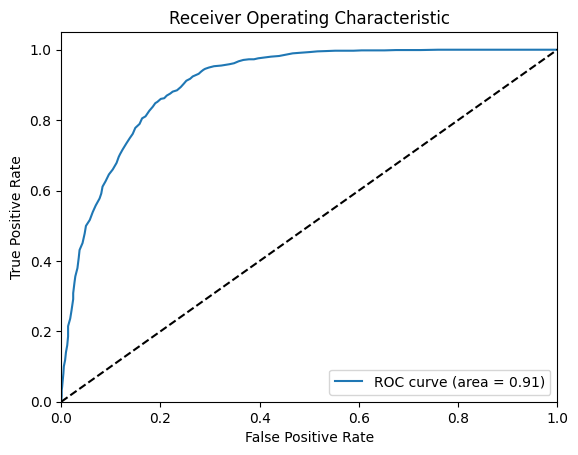

PR AUC: 0.8711278165945212


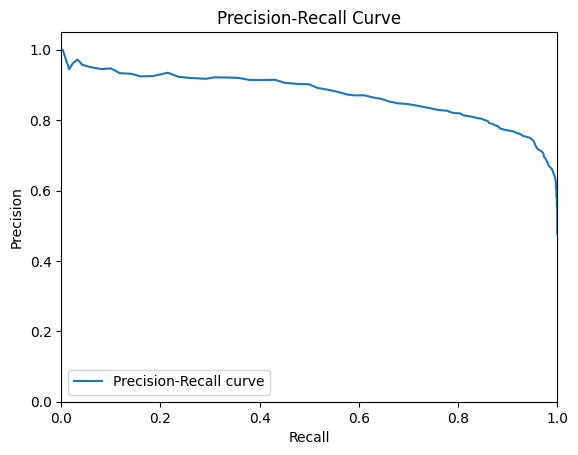

 54%|█████▍    | 7/13 [00:26<00:17,  2.93s/it]


Confusion Matrix:
 [[942 224]
 [242 825]]


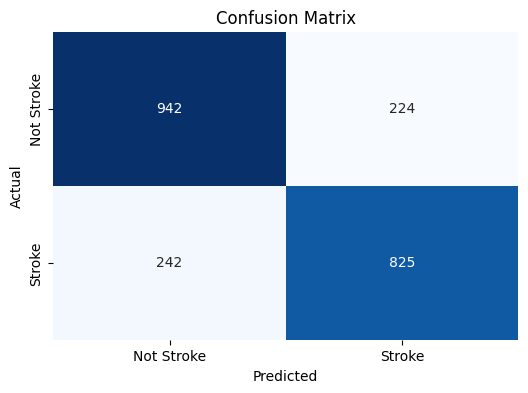


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.80      0.81      0.80      1166
      Stroke       0.79      0.77      0.78      1067

    accuracy                           0.79      2233
   macro avg       0.79      0.79      0.79      2233
weighted avg       0.79      0.79      0.79      2233

ROC-AUC: 0.8746007224371887


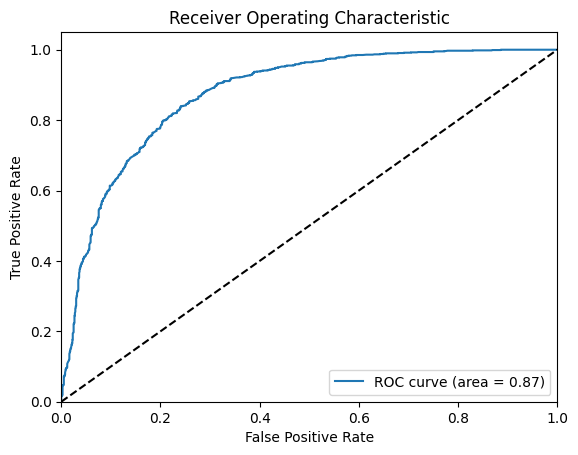

PR AUC: 0.8371880150450572


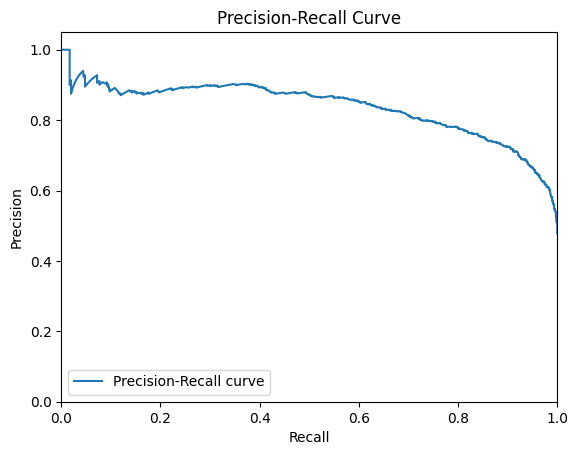

 62%|██████▏   | 8/13 [00:27<00:11,  2.28s/it]


Confusion Matrix:
 [[942 224]
 [166 901]]


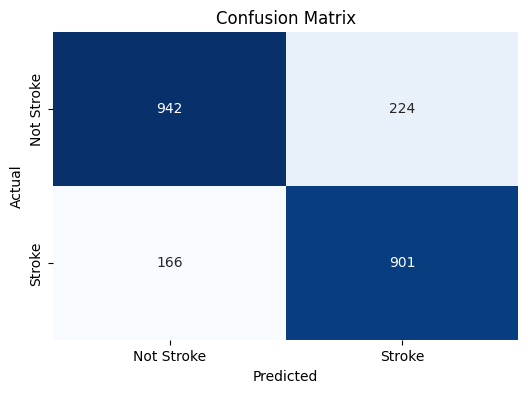


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.85      0.81      0.83      1166
      Stroke       0.80      0.84      0.82      1067

    accuracy                           0.83      2233
   macro avg       0.83      0.83      0.83      2233
weighted avg       0.83      0.83      0.83      2233

ROC-AUC: 0.9085101782622604


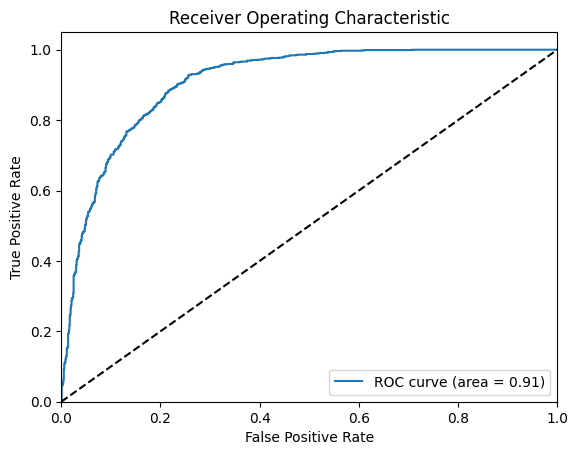

PR AUC: 0.8766449926690107


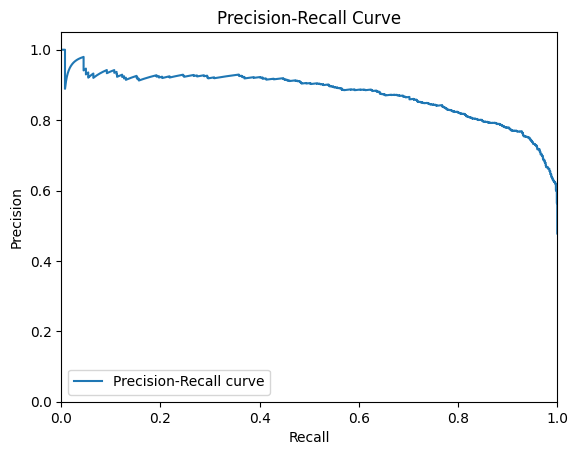

 69%|██████▉   | 9/13 [00:29<00:08,  2.16s/it]


Confusion Matrix:
 [[957 209]
 [144 923]]


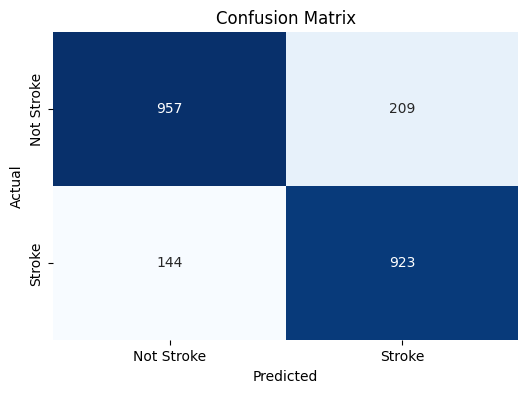


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.82      0.84      1166
      Stroke       0.82      0.87      0.84      1067

    accuracy                           0.84      2233
   macro avg       0.84      0.84      0.84      2233
weighted avg       0.84      0.84      0.84      2233

ROC-AUC: 0.919381700508471


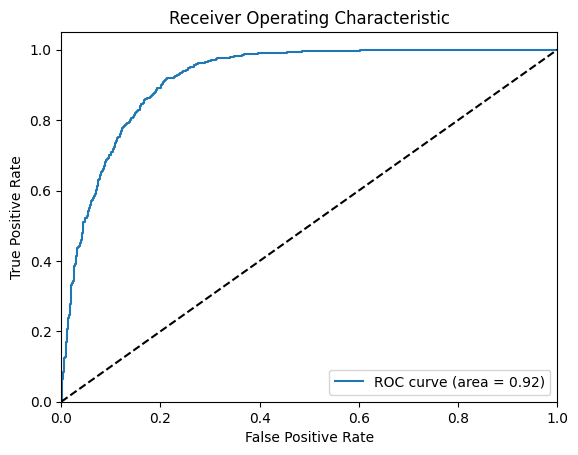

PR AUC: 0.8867562483048582


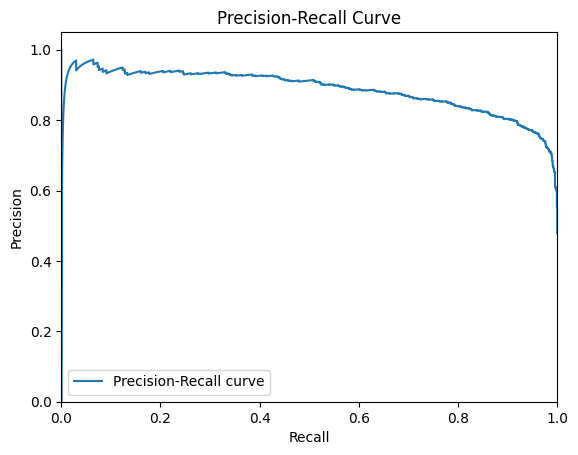

 77%|███████▋  | 10/13 [00:30<00:05,  1.76s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [20:12:03] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[968 198]
 [151 916]]


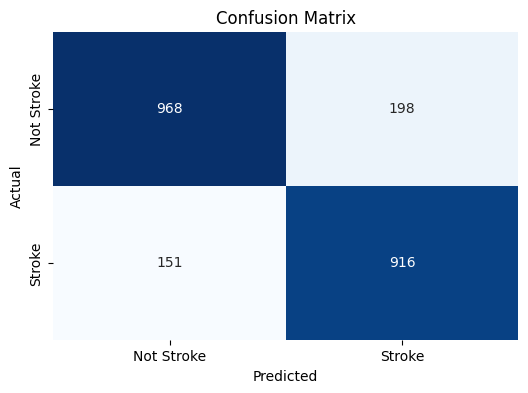


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.83      0.85      1166
      Stroke       0.82      0.86      0.84      1067

    accuracy                           0.84      2233
   macro avg       0.84      0.84      0.84      2233
weighted avg       0.84      0.84      0.84      2233

ROC-AUC: 0.9157839825997772


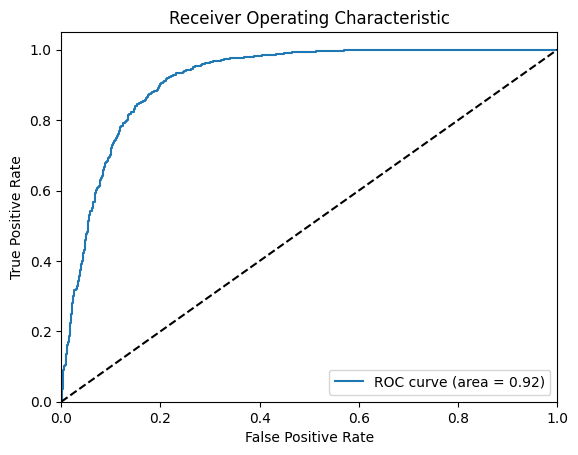

PR AUC: 0.8763659035547554


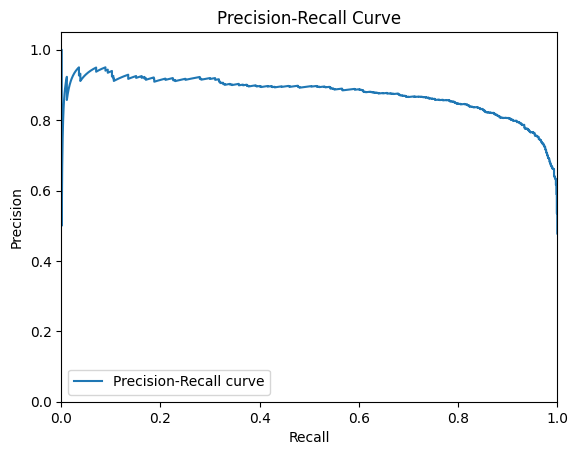

 85%|████████▍ | 11/13 [00:31<00:02,  1.43s/it]


Confusion Matrix:
 [[970 196]
 [139 928]]


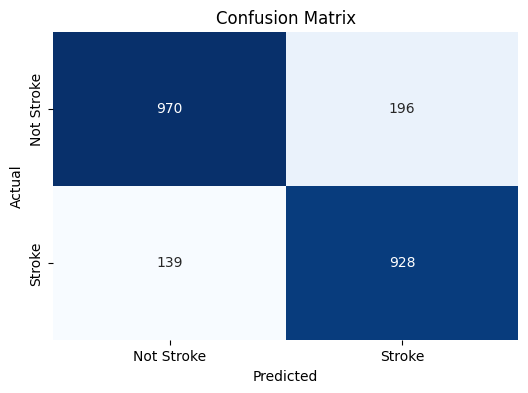


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.83      0.85      1166
      Stroke       0.83      0.87      0.85      1067

    accuracy                           0.85      2233
   macro avg       0.85      0.85      0.85      2233
weighted avg       0.85      0.85      0.85      2233

ROC-AUC: 0.92276802435774


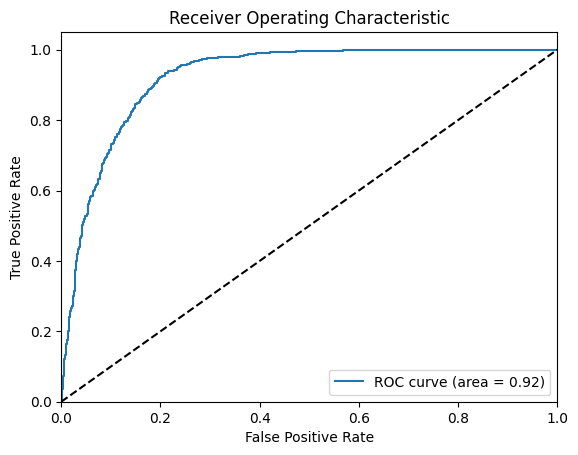

PR AUC: 0.8878339293843491


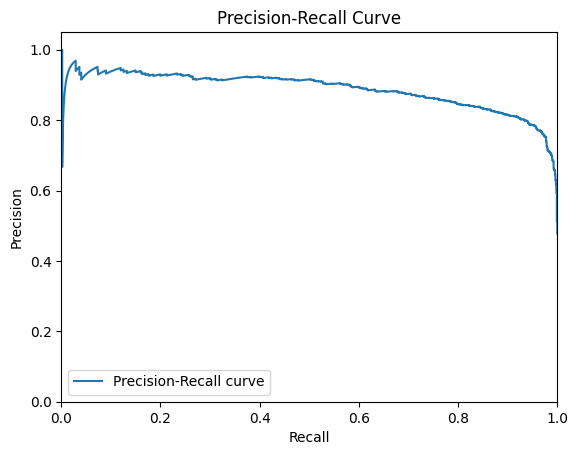

 92%|█████████▏| 12/13 [00:34<00:02,  2.17s/it]

[LightGBM] [Info] Number of positive: 4222, number of negative: 4707
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001481 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 969
[LightGBM] [Info] Number of data points in the train set: 8929, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.472841 -> initscore=-0.108742
[LightGBM] [Info] Start training from score -0.108742

Confusion Matrix:
 [[952 214]
 [142 925]]


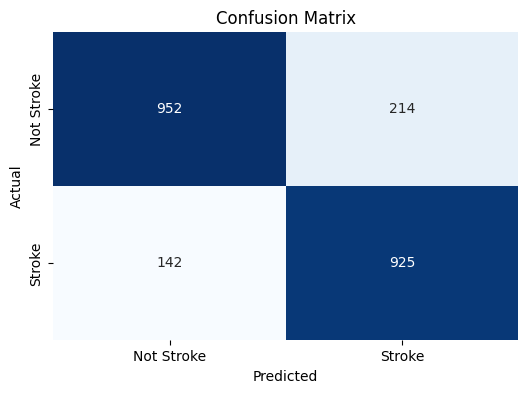


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.82      0.84      1166
      Stroke       0.81      0.87      0.84      1067

    accuracy                           0.84      2233
   macro avg       0.84      0.84      0.84      2233
weighted avg       0.84      0.84      0.84      2233

ROC-AUC: 0.9186550836654284


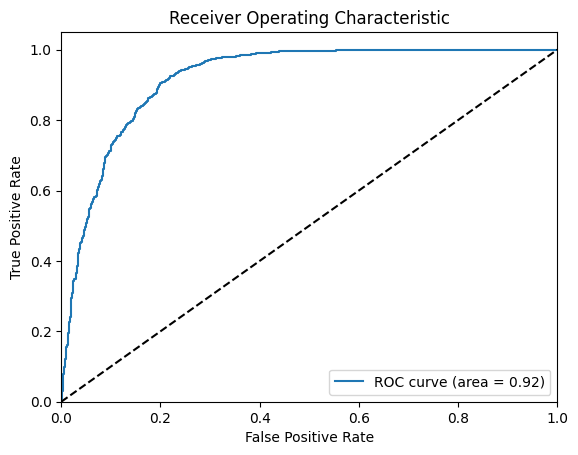

PR AUC: 0.8835778901188349


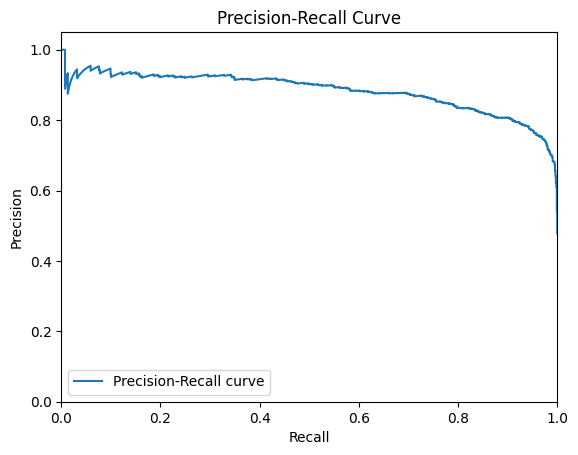

100%|██████████| 13/13 [00:35<00:00,  2.75s/it]


In [27]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred  = model.predict(x_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(x_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }
    results = {}

for name, model in tqdm(models.items()):
    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred  = model.predict(x_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(x_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [20:12:16] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[926 240]
 [132 935]]


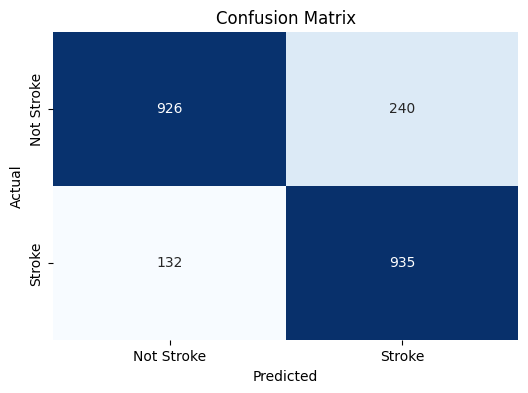


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.79      0.83      1166
      Stroke       0.80      0.88      0.83      1067

    accuracy                           0.83      2233
   macro avg       0.84      0.84      0.83      2233
weighted avg       0.84      0.83      0.83      2233

ROC-AUC: 0.9066956456038879


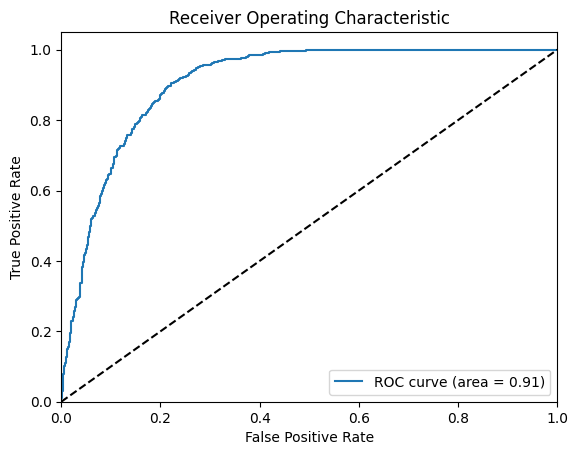

PR AUC: 0.8658994035730103


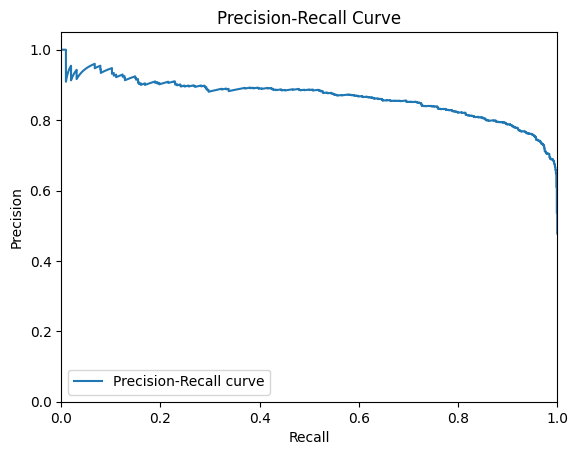

In [28]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(x_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(x_train)
stack_auto_test_pred  = stack_auto.predict(x_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(x_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [29]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
CatBoost,0.910964,0.849978,0.888109,0.825623,0.928707,0.869728,0.907954,0.847102,0.911878,0.850816,0.922768,0.887834
XGBoost,0.963378,0.843708,0.950706,0.822262,0.972999,0.858482,0.961723,0.839982,0.963873,0.844335,0.915784,0.876366
Hist Gradient Boosting,0.911636,0.841917,0.878501,0.815371,0.943629,0.865042,0.909901,0.839472,0.913284,0.842898,0.919382,0.886756
LightGBM,0.911188,0.840573,0.877228,0.812116,0.944339,0.866917,0.909547,0.838622,0.912896,0.841692,0.918655,0.883578
Random Forest,1.000000,0.836991,1.000000,0.806987,1.000000,0.865979,1.000000,0.835443,1.000000,0.838221,0.908156,0.870905
Stacking Classifier,0.900773,0.833408,0.846202,0.795745,0.965656,0.876289,0.901991,0.834077,0.904115,0.835228,0.906696,0.865899
Extra Trees,1.000000,0.828482,1.000000,0.803730,1.000000,0.848172,1.000000,0.825353,1.000000,0.829318,0.905379,0.871128
Gradient Boosting,0.859671,0.825347,0.833821,0.800889,0.878257,0.844424,0.855462,0.822080,0.860628,0.826157,0.908510,0.876645
SVC,0.838056,0.808330,0.811770,0.784506,0.855992,0.825679,0.833295,0.804566,0.838980,0.809066,0.883132,0.840377
AdaBoost,0.804457,0.791312,0.798889,0.786463,0.783752,0.773196,0.791248,0.779773,0.803391,0.790543,0.874601,0.837188


<Axes: >

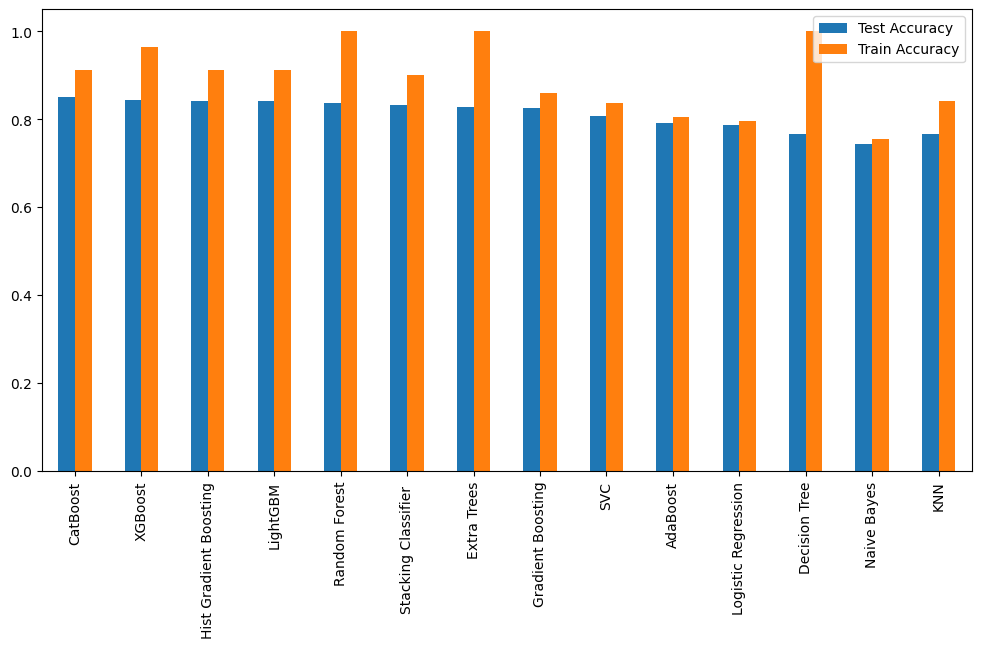

In [30]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

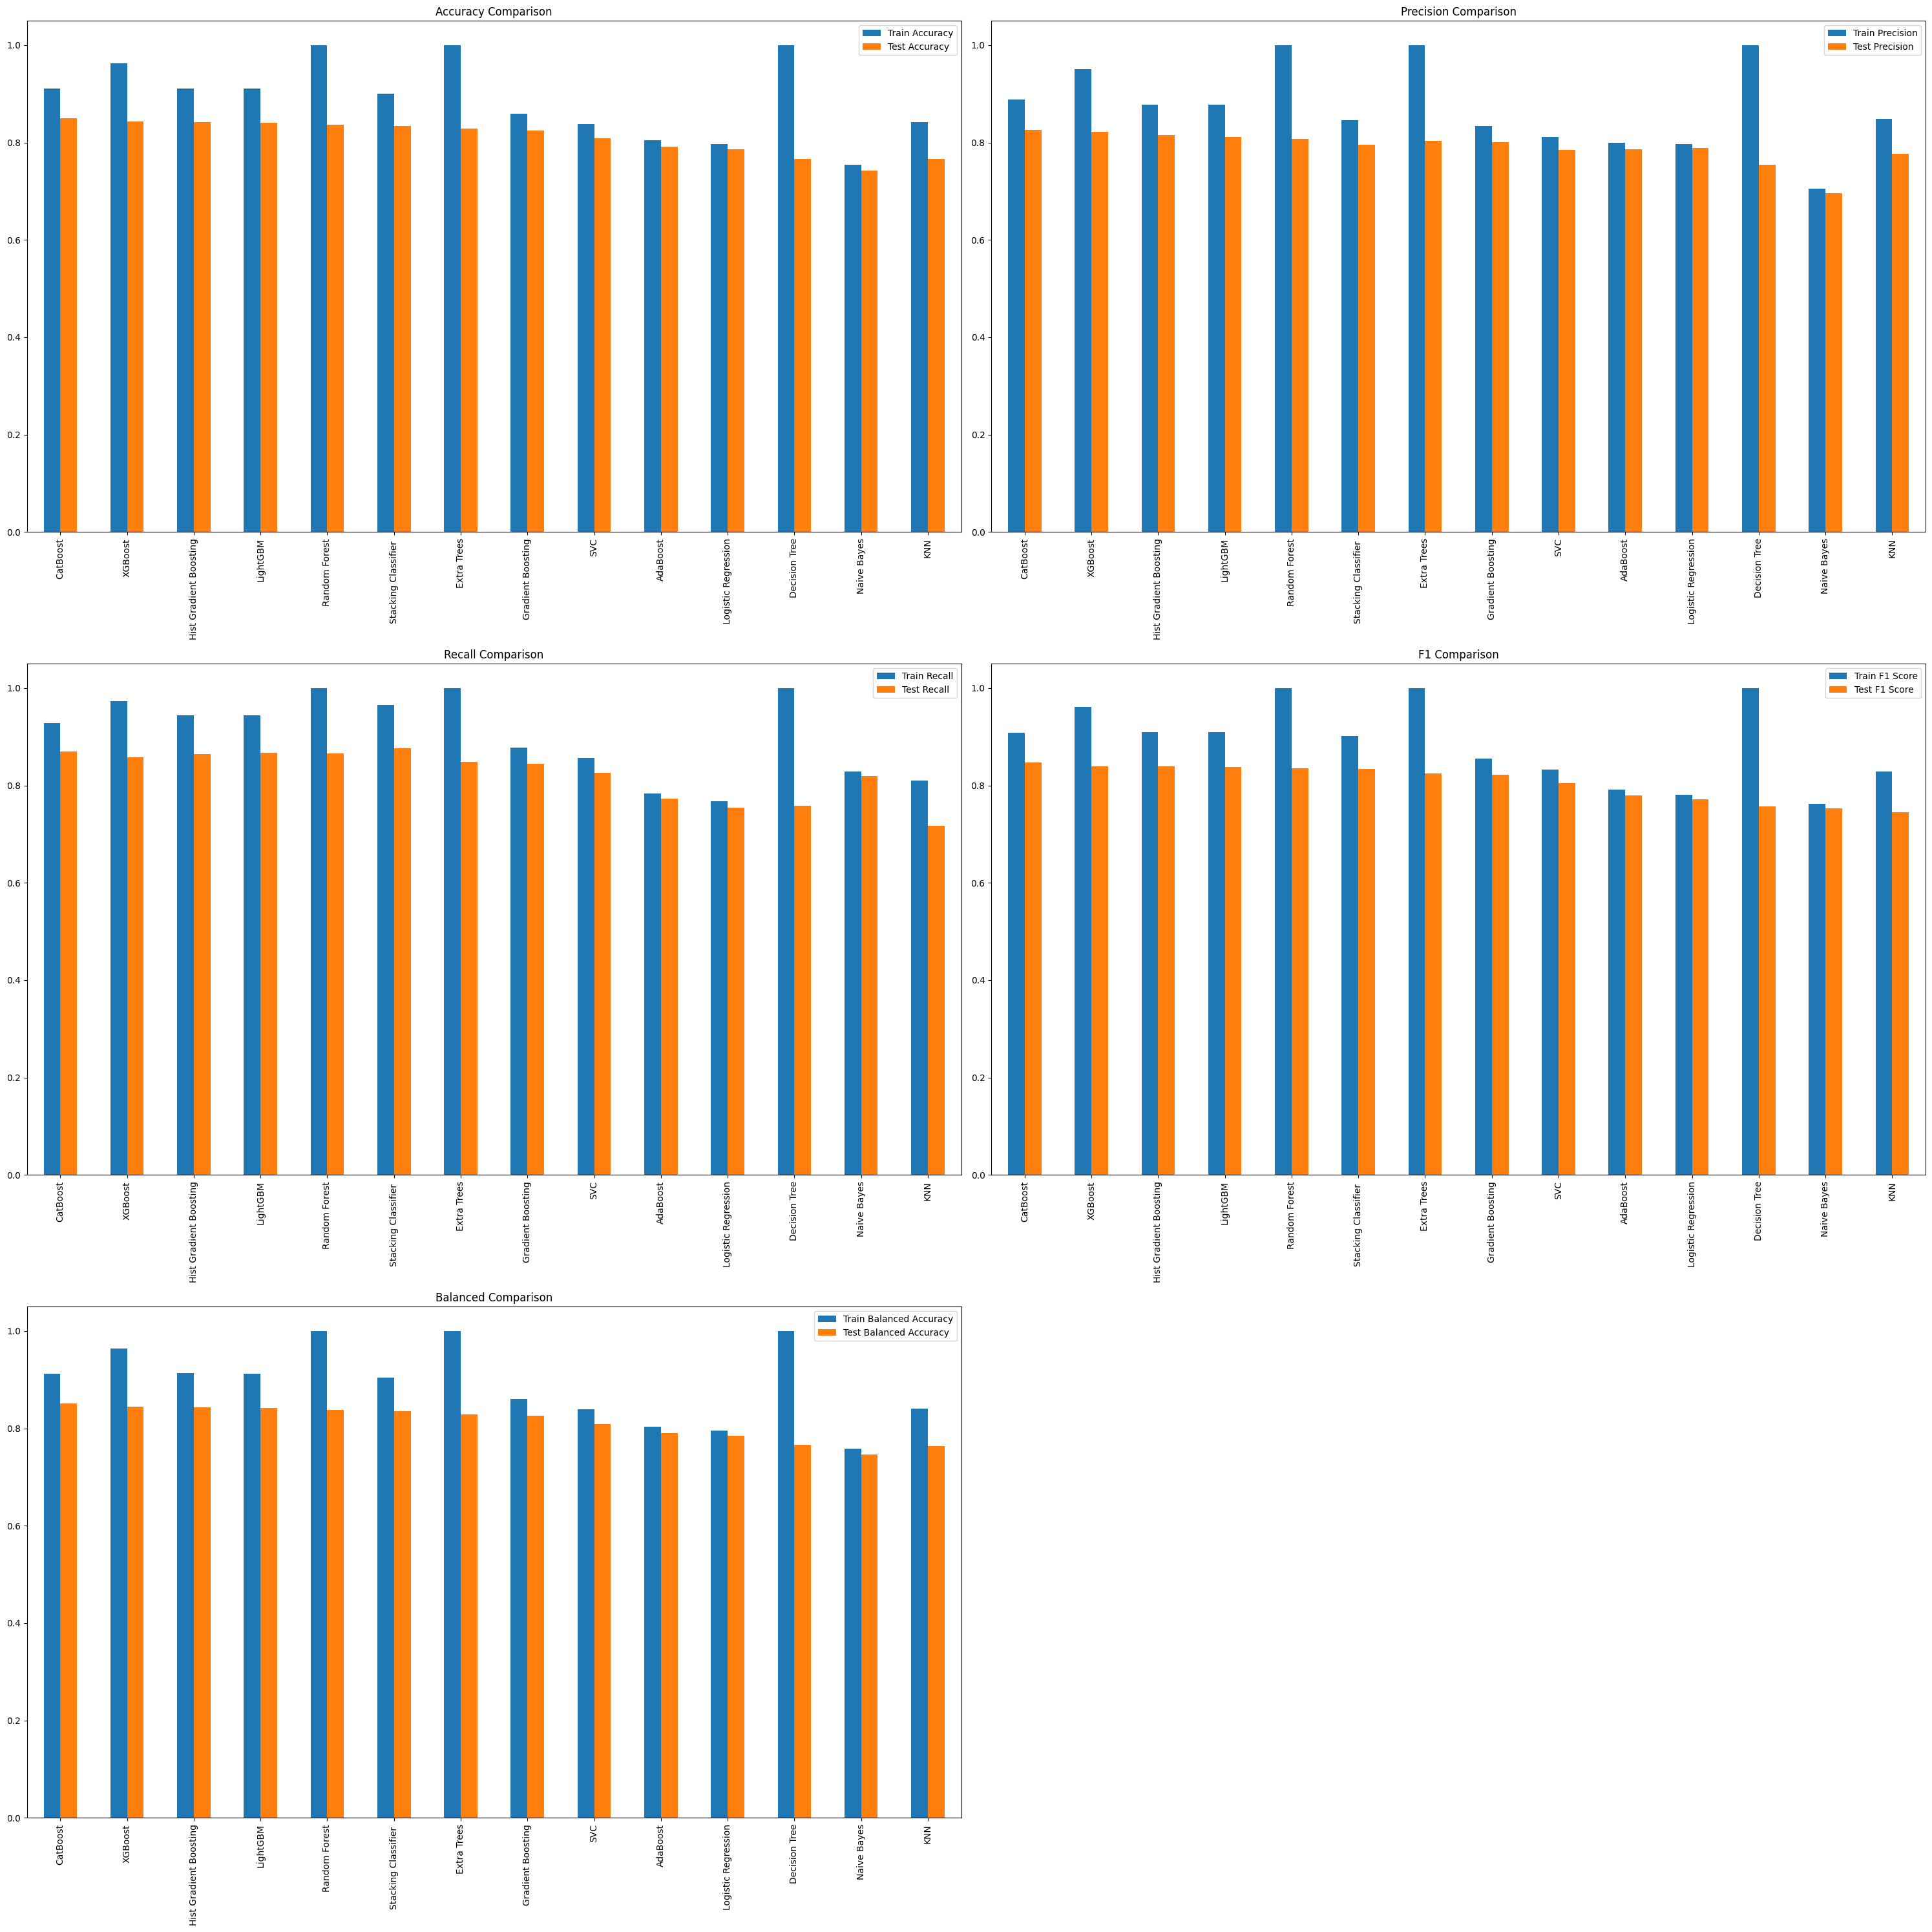

In [31]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()

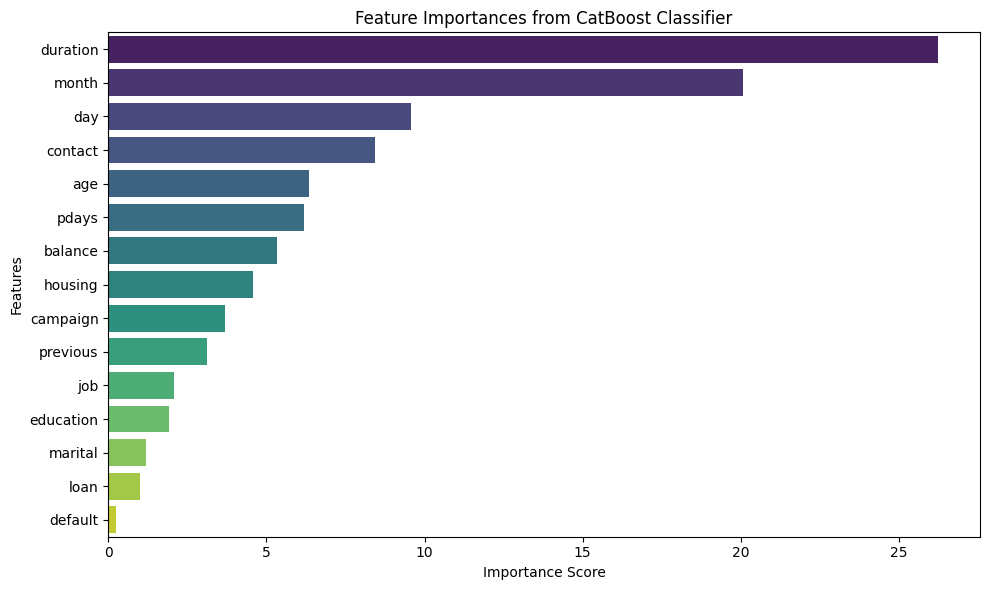

,Feature,Importance
11,duration,26.247095
10,month,20.054457
9,day,9.572276
8,contact,8.427696
0,age,6.341133
13,pdays,6.189597
5,balance,5.321165
6,housing,4.584870
12,campaign,3.676026
14,previous,3.132207


In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

catboost_model = models["CatBoost"]
catboost_model.fit(x_train, y_train)

importances = catboost_model.feature_importances_
feature_names = x_train.columns

fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=fi_df, palette='viridis', hue='Feature', legend=False)
plt.title('Feature Importances from CatBoost Classifier')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

display(fi_df)

In [33]:
pip install gradio

In [34]:
import gradio as gr
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler

# We will use the trained stack_auto model and our label encoders and scalar from previous cells.
# 'poutcome' has been removed from our features list.

def predict_deposit(age, job, marital, education, default, balance, housing, loan, contact, day, month, duration, campaign, pdays, previous):
    # 1. Create a dictionary from inputs (excluding poutcome)
    input_dict = {
        'age': [float(age)],
        'job': [str(job)],
        'marital': [str(marital)],
        'education': [str(education)],
        'default': [str(default)],
        'balance': [float(balance)],
        'housing': [str(housing)],
        'loan': [str(loan)],
        'contact': [str(contact)],
        'day': [float(day)],
        'month': [str(month)],
        'duration': [float(duration)],
        'campaign': [float(campaign)],
        'pdays': [float(pdays)],
        'previous': [float(previous)]
    }

    input_df = pd.DataFrame(input_dict)

    # 2. Apply Label Encoding to categorical features (excluding poutcome)
    cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month']

    for col in cat_cols:
        combined_series = pd.concat([x[col], x_test[col] if 'x_test' in globals() else x[col]]).astype(str)
        le_temp = LabelEncoder()
        le_temp.fit(combined_series)
        input_df[col] = le_temp.transform(input_df[col].astype(str))

    # 3. Apply StandardScaler (numerical features scaling)
    for i in x.select_dtypes(include='number').columns:
        scaler_temp = StandardScaler()
        scaler_temp.fit(x[[i]])
        input_df[[i]] = scaler_temp.transform(input_df[[i]])

    # Reorder columns to match train features exactly
    input_df = input_df[x_train.columns]

    # 4. Predict probability and class
    pred_prob = stack_auto.predict_proba(input_df)[0][1]
    pred_class = stack_auto.predict(input_df)[0]

    # 5. Format results
    result = "Yes (Deposit)" if pred_class == 1 else "No (No Deposit)"
    return f"Prediction: {result}\nProbability of Deposit: {pred_prob:.2%}"

# Retrieve original category options for dropdowns
jobs = list(df['job'].unique())
maritals = list(df['marital'].unique())
educations = list(df['education'].unique())
defaults = list(df['default'].unique())
housings = list(df['housing'].unique())
loans = list(df['loan'].unique())
contacts = list(df['contact'].unique())
months = list(df['month'].unique())

# Create Gradio Interface (without poutcome)
interface = gr.Interface(
    fn=predict_deposit,
    inputs=[
        gr.Slider(minimum=18, maximum=100, step=1, label="Age"),
        gr.Dropdown(choices=jobs, label="Job"),
        gr.Dropdown(choices=maritals, label="Marital Status"),
        gr.Dropdown(choices=educations, label="Education"),
        gr.Dropdown(choices=defaults, label="Has Default?"),
        gr.Number(label="Balance"),
        gr.Dropdown(choices=housings, label="Has Housing Loan?"),
        gr.Dropdown(choices=loans, label="Has Personal Loan?"),
        gr.Dropdown(choices=contacts, label="Contact Type"),
        gr.Slider(minimum=1, maximum=31, step=1, label="Day of Month"),
        gr.Dropdown(choices=months, label="Month"),
        gr.Number(label="Duration (seconds)"),
        gr.Number(label="Campaign (contacts)"),
        gr.Number(label="Pdays (-1 for never)"),
        gr.Number(label="Previous (contacts)")
    ],
    outputs=gr.Textbox(label="Prediction Result"),
    title="Bank Term Deposit Predictor",
    description="Enter the client details to predict whether they will subscribe to a term deposit."
)

# Launch the App
interface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://972038fc2fd557eeb7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
